This is the main teaching notebook for the mini public repository. It deliberately slows down and shows:

- how the flowsheet becomes graph tensors;
- which equations are implemented by the analytical simulator;
- how masks, the GNN, hierarchical actor, critic, GAE, and PPO interact;
- how a small training exercise changes the policy; and
- how to inspect the compact recorded long-run results.

## 1. Architecture and responsibility

```mermaid
flowchart TD
    NB[This notebook] --> CFG[Configuration]
    CFG --> ENV[FlowsheetEnv]
    ENV --> GRAPH[FlowsheetGraph in NetworkX]
    GRAPH --> MASK[Engineering action masks]
    GRAPH --> SIM[Custom analytical simulator]
    SIM --> OBS[Graph, global features and diagnostics]
    OBS --> PYG[PyTorch Geometric tensors]
    PYG --> GNN[GNN encoder]
    GNN --> ACTOR[Hierarchical actor]
    GNN --> CRITIC[Value critic]
    ACTOR --> ACTION[Stream, unit, parameter or partner]
    ACTION --> ENV
    SIM --> REWARD[Terminal engineering reward]
    REWARD --> ROLLOUT[Rollout collector]
    ACTOR --> ROLLOUT
    CRITIC --> ROLLOUT
    ROLLOUT --> GAE[GAE]
    GAE --> PPO[PPO and Adam]
    PPO -->|updates weights| GNN
    PPO --> SAVE[Checkpoint and training JSON]
    SAVE --> EVAL[Fixed-seed evaluation]
```

The simulator answers **what does this proposed process do?** The actor answers **what should I add next?** The critic estimates **how promising is this partial design?** PPO answers **how should the neural weights change after the collected experience?**

## 2. Set up the project and teaching helpers

In [1]:
from pathlib import Path
from copy import deepcopy
from datetime import datetime
import inspect
import json
import os
import sys
import textwrap
import uuid

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch_geometric
from IPython.display import Code, Image, Markdown, display

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT = next((q for p in candidates for q in [p]
                if (q/"src"/"flowsheet_rl").is_dir()), None)
assert PROJECT is not None, "Launch Jupyter from the repository root or notebooks directory."
os.chdir(PROJECT)
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT/"notebooks"/".mpl-cache"))

from flowsheet_rl.actions import Action, Unit, UNIT_NAMES, action_masks
from flowsheet_rl.baselines import RandomValidPolicy, RuleBasedPolicy
from flowsheet_rl.chemistry import Stream
from flowsheet_rl.config import ExperimentConfig, EnvironmentConfig, TrainConfig
from flowsheet_rl.environment import FlowsheetEnv
from flowsheet_rl.evaluation import begin_experiment, evaluate_policy
from flowsheet_rl.graph_state import FlowsheetGraph, to_pyg
from flowsheet_rl.inspection import inspect_decision, stream_table
from flowsheet_rl.models import ActorCritic
from flowsheet_rl.models.gnn_encoder import DirectedLayer, GNNEncoder
from flowsheet_rl.rewards import reward_breakdown
from flowsheet_rl.simulators.low_fidelity import LowFidelitySimulator
from flowsheet_rl.training.advantages import generalized_advantages
from flowsheet_rl.training.checkpoints import load_checkpoint
from flowsheet_rl.training.ppo import seed_everything, train
from flowsheet_rl.training.rollout import Collector
from flowsheet_rl.units import mixer, reactor, separator, thermal
from flowsheet_rl.visualization import plot_flowsheet

seed_everything(7)
print("Project:", PROJECT)
print("Python:", sys.executable)
print("Torch:", torch.__version__, "| PyG:", torch_geometric.__version__)
print("CUDA:", torch.cuda.is_available(), "| This validated runner uses CPU.")

<project>\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
<project>\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Project: <project>
Python: <project>\.venv\Scripts\python.exe
Torch: 2.14.0+cpu | PyG: 2.8.0.post1
CUDA: False | This validated runner uses CPU.


In [2]:
def show_source(obj):
    # Display the exact implementation currently imported by this notebook.
    display(Code(textwrap.dedent(inspect.getsource(obj)), language="python"))


def show_file_lines(relative_path, first, last):
    # Display selected one-based lines from a project source file.
    path = PROJECT / relative_path
    lines = path.read_text(encoding="utf-8").splitlines()
    excerpt = "\n".join(f"{i:4d}  {lines[i-1]}" for i in range(first, min(last, len(lines)) + 1))
    display(Code(excerpt, language="python"))


def show_records(rows, columns):
    # Display a small list of dictionaries without requiring pandas.
    def fmt(value):
        if isinstance(value, float):
            return f"{value:.5g}"
        return str(value)
    header = "|" + "|".join(columns) + "|"
    rule = "|" + "|".join(["---"] * len(columns)) + "|"
    body = ["|" + "|".join(fmt(row.get(column, "")) for column in columns) + "|" for row in rows]
    display(Markdown("\n".join([header, rule, *body])))


session = PROJECT/"runs"/"notebook_sessions"/(
    datetime.now().strftime("%Y%m%d_%H%M%S") + "_learning_" + uuid.uuid4().hex[:6]
)
session.mkdir(parents=True, exist_ok=False)
print("Teaching outputs:", session)

Teaching outputs: <original-runs>\notebook_sessions\20260928_191526_learning_1a731e


### Which parts come from libraries, and which parts did we write?

| Layer | Library or project code | What it contributes |
|---|---|---|
| Numerical arrays | NumPy | vectors, masks and calculations |
| Editable topology | NetworkX | directed graph storage and topological sorting |
| RL interface | Gymnasium | standard `reset()` and `step()` contract |
| Neural networks | PyTorch | layers, gradients and Adam optimizer |
| Graph neural network support | PyTorch Geometric | message passing and graph batching |
| Process equations | **Project code** in `units/` | mixer, thermal, reactor and separator equations |
| Flowsheet simulator | **Project code** in `simulators/` | sequential calculation, balances and feasibility |
| Design logic | **Project code** in `actions.py` and `graph_state.py` | masks, topology changes and validation |
| RL architecture | **Project code** in `models/` and `training/` | hierarchical policy, critic, GAE and PPO |

The libraries save us from writing generic graph containers and neural-network machinery. The engineering assumptions remain visible in our own short Python functions.

## 3. Configuration: define the experiment before creating objects

In [3]:
SEED = 103
config = ExperimentConfig(
    environment=EnvironmentConfig(
        feed_a=1.0,
        feed_b=1.0,
        feed_variation=0.1,
        feed_temperature=300.0,
        fidelity="source",
    )
)
print(config)
print("Maximum graph nodes:", config.environment.max_nodes)
print("Purity requirement:", config.environment.purity_min)
print("Recovery requirement:", config.environment.recovery_min)

ExperimentConfig(environment=EnvironmentConfig(fidelity='source', max_units=8, max_steps=16, feed_a=1.0, feed_b=1.0, feed_variation=0.1, feed_temperature=300.0, purity_min=0.9, recovery_min=0.6, balance_tolerance=1e-09), reward=RewardConfig(product_value=10.0, utility=0.2, capital=0.3, complexity=0.05, success=2.0, specification=4.0, open_stream=2.0, failure=10.0, step=0.01), model=ModelConfig(hidden_dim=32, layers=2), train=TrainConfig(seed=7, updates=4, rollout_steps=64, epochs=2, minibatch_size=16, learning_rate=0.0003, gamma=0.99, gae_lambda=0.95, clip_ratio=0.2, entropy_coef=0.01, value_coef=0.5, max_grad_norm=0.5, freeze_encoder_updates=0, checkpoint_interval=1, evaluation_interval=1))
Maximum graph nodes: 20
Purity requirement: 0.9
Recovery requirement: 0.6


`ExperimentConfig` contains four dataclasses: environment, reward, model and training settings. Dataclasses give names to values and validate them once. For example, negative feeds, unknown fidelity names and specification fractions above one are rejected immediately.

The default maximum node count is

$$N_{max}=4+2N_{units,max}=4+2(8)=20.$$

The graph tensors still use only the nodes that currently exist. The maximum is needed for bounded action masks.

In [4]:
show_source(EnvironmentConfig)

@dataclass
class EnvironmentConfig:
    fidelity: str = "source"
    max_units: int = 8
    max_steps: int = 16
    feed_a: float = 1.0
    feed_b: float = 1.0
    feed_variation: float = 0.1
    feed_temperature: float = 300.0
    purity_min: float = 0.9
    recovery_min: float = 0.6
    balance_tolerance: float = 1e-9

    def __post_init__(self):
        if self.fidelity not in ("source", "target"):
            raise ValueError("fidelity must be source or target")
        if self.max_units < 1 or self.max_steps < 1:
            raise ValueError("positive construction budgets required")
        values = asdict(self)
        if any(not math.isfinite(v) for v in values.values() if isinstance(v, (float, int))):
            raise ValueError("configuration must be finite")
        if min(self.feed_a, self.feed_b, self.balance_tolerance) <= 0:
            raise ValueError("positive feeds and tolerance required")
        if not 0 <= self.feed_variation < 1 or not 280 <= self.feed_temperature <= 450:
            raise ValueError("invalid feed conditions")
        if not all(0 < x <= 1 for x in (self.purity_min, self.recovery_min)):
            raise ValueError("specifications must lie in (0,1]")

    @property
    def max_nodes(self):
        return 4 + 2 * self.max_units

## 4. Reset: create the initial graph and calculate its streams

0: feed -> [1]
1: open -> []
2: feed -> [3]
3: open -> []
Open nodes: [1, 3]
Actual sampled feed flow [A, B, C]: [0.96253665 0.94486364 0.        ]


|source|target|A|B|C|total|temperature_K|
|---|---|---|---|---|---|---|
|0|1|0.96254|0|0|0.96254|300|
|2|3|0|0.94486|0|0.94486|300|

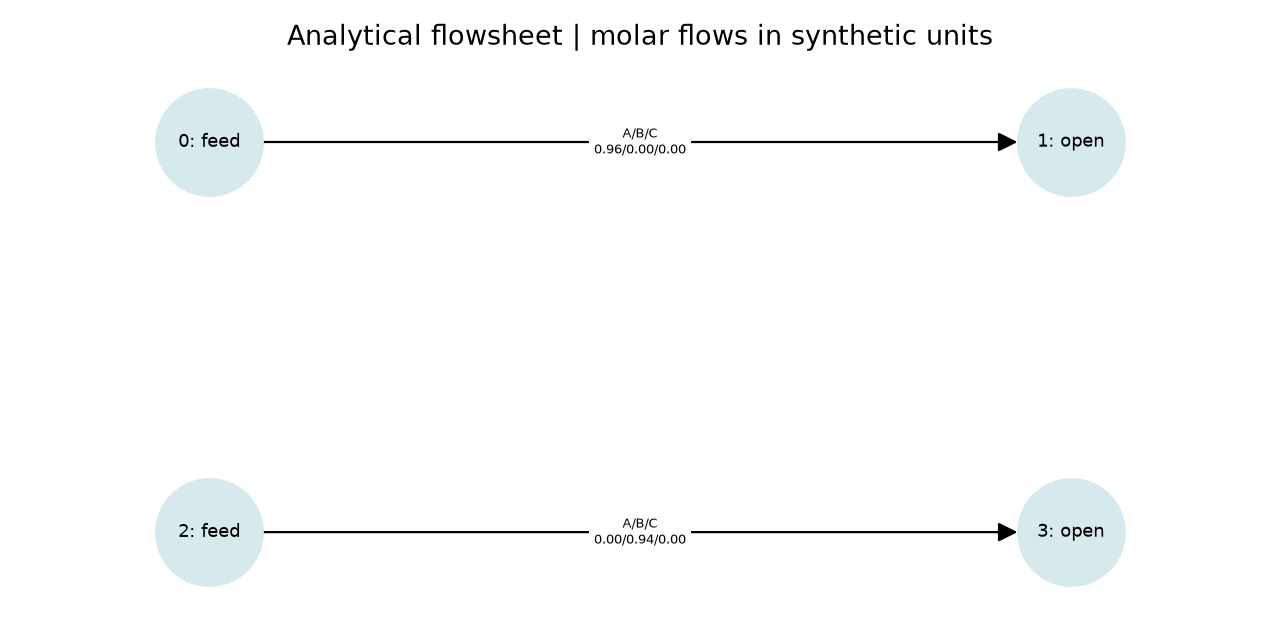

In [5]:
env = FlowsheetEnv(config.environment, config.reward)
observation, reset_info = env.reset(seed=SEED)

print(env.render())
print("Open nodes:", env.state.open_nodes)
print("Actual sampled feed flow [A, B, C]:", env.state.feed_flow)
show_records(stream_table(env.state), ["source", "target", "A", "B", "C", "total", "temperature_K"])

initial_png = session/"00_initial_graph.png"
plot_flowsheet(env.state.record(), initial_png)
display(Image(filename=str(initial_png)))

`env.reset(seed=103)` does more than clear a counter. It samples reproducible feed rates, creates two feed nodes and two open boundaries, runs the simulator once, and builds the first observation.

An **open node** means that a material stream exists but has not yet been connected to equipment, product or purge.

### Reveal the implementation of reset and initial graph construction

In [6]:
show_source(FlowsheetEnv.reset)
show_source(FlowsheetGraph.initial)

def reset(self, *, seed=None, options=None):
    super().reset(seed=seed)
    cfg = self.config
    rates = np.array([cfg.feed_a, cfg.feed_b]) * self.np_random.uniform(
        1 - cfg.feed_variation, 1 + cfg.feed_variation, 2
    )
    self.state = FlowsheetGraph.initial(*rates, cfg.feed_temperature)
    self.result = self.simulator.simulate(self.state, cfg)
    self.simulator_calls = 1
    self.done = False
    self.history = []
    return self.observation(), self.info("reset", {})

@classmethod
def initial(cls, feed_a, feed_b, temperature=300.0):
    graph = nx.DiGraph()
    for i, flow in enumerate(([feed_a, 0, 0], [0, feed_b, 0])):
        source, boundary = 2 * i, 2 * i + 1
        stream = Stream(np.array(flow), temperature)
        graph.add_node(source, kind="feed", feed=stream, stream=stream, parameter=0.0)
        graph.add_node(boundary, kind="open", stream=stream, parameter=0.0)
        graph.add_edge(source, boundary, port=0, stream=stream)
    return cls(graph)

## 5. Masks: show the choices that engineering rules permit

In [7]:
masks = env.action_masks()
stop_index = config.environment.max_nodes
print("Valid stream locations:", np.flatnonzero(masks["stream_mask"]).tolist())
print("STOP index:", stop_index)
for node in env.state.open_nodes:
    valid_units = [UNIT_NAMES[i] for i in np.flatnonzero(masks["unit_mask"][node])]
    incoming = next(env.state.graph.predecessors(node))
    stream = env.state.graph.edges[incoming, node]["stream"]
    print(f"Open node {node}: flow={stream.flow} -> {valid_units}")

Valid stream locations: [1, 3, 20]
STOP index: 20
Open node 1: flow=[0.96253665 0.         0.        ] -> ['mixer', 'thermal', 'purge']
Open node 3: flow=[0.         0.94486364 0.        ] -> ['mixer', 'thermal', 'purge']


Initially, neither pure feed contains both A and B, so a reactor is masked. Neither contains C, so separator and product are masked. Mixing and purging are meaningful.

Known impossibilities belong in rules and masks. The agent learns preferences among valid actions instead of wasting experience on impossible port connections or meaningless unit choices.

In [8]:
show_source(action_masks)

def action_masks(state, config):
    stream = np.zeros(config.max_nodes + 1, dtype=bool)
    units = np.zeros((config.max_nodes, len(Unit)), dtype=bool)
    stream[config.max_nodes] = True  # STOP remains available, including after closure.
    for n in state.open_nodes:
        stream[n] = True
        flow = state.graph.nodes[n]["stream"].flow
        units[n, Unit.PURGE] = True
        # Zero-C branches cannot be products; purity is NOT an action validity criterion.
        units[n, Unit.PRODUCT] = flow[2] > 1e-12
        if state.num_units < config.max_units:
            units[n, Unit.THERMAL] = True
            units[n, Unit.REACTOR] = min(flow[0], flow[1]) > 1e-12
            units[n, Unit.SEPARATOR] = flow[2] > 1e-12
            units[n, Unit.MIXER] = len(state.open_nodes) > 1
    return {"stream_mask": stream, "unit_mask": units}

## 6. The custom process simulator: inspect and calculate the equations

No process-simulation package supplies these models. They are intentionally small functions in `src/flowsheet_rl/units` so every assumption can be inspected.

For a normalized decision $p\in[0,1]$:

**Thermal unit**

$$T_{out}=280+170p,$$

$$Q=0.01F_{total}|T_{out}-T_{in}|.$$

**Reactor, $A+B\rightarrow C$**

$$\tau=0.1+3.9p,$$

$$k=0.6\exp\left(\frac{T-330}{80}\right),$$

$$X=\min(0.98,1-e^{-k\tau}),\quad \xi=X\min(F_A,F_B),$$

$$\mathbf F_{out}=\mathbf F_{in}+[-1,-1,+1]\xi.$$

**Separator**

$$r_C=0.7+0.28p,\qquad \ell=0.02+0.08(1-p),$$

$$\mathbf F_{rich}=\mathbf F\odot[\ell,\ell,r_C],$$

$$\mathbf F_{residual}=\mathbf F-\mathbf F_{rich}.$$

These are synthetic educational equations, not calibrated industrial correlations.

In [9]:
show_source(thermal)
show_source(reactor)
show_source(separator)

def thermal(stream, parameter, utility_factor=1.0):
    temperature = 280.0 + 170.0 * bounded_parameter(parameter)
    energy = stream.total * abs(temperature - stream.temperature) * 0.01 * utility_factor
    return UnitResult((Stream(stream.flow, temperature, stream.pressure),), energy, 0.3)

def reactor(stream, parameter, target=False):
    residence = 0.1 + 3.9 * bounded_parameter(parameter)
    rate = 0.6 * np.exp((stream.temperature - 330.0) / 80.0)
    if target:
        rate *= 0.8 / (1.0 + 0.15 * stream.flow[2])
    conversion = min(0.98, float(-np.expm1(-rate * residence)))
    extent = conversion * min(stream.flow[0], stream.flow[1])
    flow = stream.flow + STOICHIOMETRY * extent
    energy = 0.1 * residence * stream.total + 0.2 * extent
    return UnitResult(
        (Stream(flow, stream.temperature, stream.pressure),),
        energy * (1.2 if target else 1.0),
        1.0 + 0.1 * residence,
        float(extent),
        conversion,
    )

def separator(stream, parameter, target=False):
    parameter = bounded_parameter(parameter)
    recovery = 0.7 + 0.28 * parameter
    leakage = 0.02 + 0.08 * (1.0 - parameter)
    if target:
        recovery -= 0.03 * parameter**2
        leakage *= 1.2
    fractions = np.array([leakage, leakage, recovery])
    rich = Stream(stream.flow * fractions, stream.temperature, stream.pressure)
    residual = Stream(stream.flow * (1.0 - fractions), stream.temperature, stream.pressure)
    energy = stream.total * (0.2 + parameter**2) * (1.3 if target else 1.0)
    return UnitResult((rich, residual), energy, 0.6 + 0.3 * parameter, performance=recovery)

In [10]:
# Calculate the reference route directly, before putting it inside a flowsheet.
mixed = mixer((Stream(np.array([1.0, 0.0, 0.0])), Stream(np.array([0.0, 1.0, 0.0]))))
heated = thermal(mixed.outputs[0], parameter=90/170)
reacted = reactor(heated.outputs[0], parameter=0.85)
separated = separator(reacted.outputs[0], parameter=0.9)

print("Mixed flow:", mixed.outputs[0].flow)
print("Heated temperature:", heated.outputs[0].temperature, "K")
print("Reactor conversion:", reacted.performance)
print("Reaction extent:", reacted.extent)
print("Reactor outlet:", reacted.outputs[0].flow)
print("C-rich outlet:", separated.outputs[0].flow)
print("Residual outlet:", separated.outputs[1].flow)
print("Unit balance residuals:")
print(" mixer   ", mixed.residual((Stream(np.array([1.,0.,0.])), Stream(np.array([0.,1.,0.])))))
print(" thermal ", heated.residual(mixed.outputs))
print(" reactor ", reacted.residual(heated.outputs))
print(" separator", separated.residual(reacted.outputs))

Mixed flow: [1. 1. 0.]
Heated temperature: 370.0 K
Reactor conversion: 0.9658922239374613
Reaction extent: 0.9658922239374613
Reactor outlet: [0.03410778 0.03410778 0.96589222]
C-rich outlet: [0.00095502 0.00095502 0.9195294 ]
Residual outlet: [0.03315276 0.03315276 0.04636283]
Unit balance residuals:
 mixer    [0. 0. 0.]
 thermal  [0. 0. 0.]
 reactor  [0. 0. 0.]
 separator [0. 0. 0.]


The direct calculation above is useful because it separates **unit mathematics** from **graph construction**. Next, the environment will reach the same route by adding units one action at a time and resimulating the full graph after every action.

### Reveal how the simulator selects unit functions and walks through the graph

In [11]:
show_source(LowFidelitySimulator.calculate)
show_source(LowFidelitySimulator.simulate)

def calculate(self, kind, inputs, parameter):
    if kind == "mixer":
        return mixer(inputs)
    if kind == "thermal":
        return thermal(inputs[0], parameter)
    if kind == "reactor":
        return reactor(inputs[0], parameter)
    if kind == "separator":
        return separator(inputs[0], parameter)
    return UnitResult((inputs[0],))

def simulate(self, state, config):
    result = SimulationResult()
    try:
        state.validate()
    except ValueError as error:
        return SimulationResult(
            calculation_status="topology_error",
            topological_valid=False,
            numerical_converged=False,
            physical_feasible=False,
            infeasibility_reason=str(error),
        )
    product = np.zeros(3)
    frontier = np.zeros(3)
    g = state.graph
    try:
        with np.errstate(over="raise", invalid="raise", divide="raise"):
            for n in nx.topological_sort(g):
                attrs = g.nodes[n]
                kind = attrs["kind"]
                inputs = [g.edges[s, n]["stream"] for s in sorted(g.predecessors(n))]
                if kind == "feed":
                    unit = UnitResult((attrs["feed"],))
                elif kind in ("open", "product", "purge"):
                    stream = inputs[0]
                    attrs["stream"] = stream
                    frontier += stream.flow
                    if kind == "product":
                        product += stream.flow
                    continue
                else:
                    unit = self.calculate(kind, inputs, attrs.get("parameter", 0.0))
                    residual = float(np.abs(unit.residual(inputs)).max())
                    result.max_unit_balance_residual = max(
                        result.max_unit_balance_residual, residual
                    )
                    result.unit_diagnostics.append(
                        {
                            "node": n,
                            "kind": kind,
                            "balance_residual": residual,
                            "energy": unit.energy,
                            "extent": unit.extent,
                        }
                    )
                attrs["stream"] = unit.outputs[0]
                attrs["performance"] = unit.performance
                result.energy += unit.energy
                result.capital_cost += unit.cost
                result.extent += unit.extent
                for _, target, edge in g.out_edges(n, data=True):
                    edge["stream"] = unit.outputs[edge["port"]]
    except (FloatingPointError, OverflowError) as error:
        result.calculation_status = "numerical_failure"
        result.numerical_converged = False
        result.physical_feasible = False
        result.infeasibility_reason = str(error)
        result.warnings.append(type(error).__name__)
        return result
    except ValueError as error:
        result.calculation_status = "physical_violation"
        result.physical_feasible = False
        result.infeasibility_reason = str(error)
        return result
    feed = state.feed_flow
    residual = feed + STOICHIOMETRY * result.extent - frontier
    result.component_balance_residual = residual.tolist()
    result.elemental_balance_residual = (ELEMENTS @ (feed - frontier)).tolist()
    result.mass_balance_residual = float(MOLECULAR_WEIGHTS @ (feed - frontier))
    result.physical_feasible = bool(
        max(
            np.abs(residual).max(),
            result.max_unit_balance_residual,
            abs(result.mass_balance_residual),
        )
        <= config.balance_tolerance
    )
    if not result.physical_feasible:
        result.calculation_status = "physical_violation"
        result.infeasibility_reason = "balance_violation"
    result.product_c = float(product[2])
    result.product_purity = float(product[2] / product.sum()) if product.sum() > 0 else 0.0
    result.product_recovery = float(product[2] / min(feed[0], feed[1]))
    result.specification_satisfied = bool(
        result.product_purity >= config.purity_min
        and result.product_recovery >= config.recovery_min
    )
    result.closed = not state.open_nodes
    result.feasible = bool(
        result.closed and result.physical_feasible and result.specification_satisfied
    )
    result.profit_proxy = (
        10 * result.produ

## 7. Build one flowsheet step by step

In [12]:
manual = FlowsheetEnv(config.environment, config.reward)
manual_obs, _ = manual.reset(seed=SEED)
manual_total_return = 0.0

def apply_and_show(action, label):
    global manual_obs, manual_total_return
    before = manual.state.open_nodes.copy()
    manual_obs, reward, terminated, truncated, info = manual.step(action)
    manual_total_return += reward
    print(label)
    print("Action:", action)
    print("Open nodes before:", before, "| after:", manual.state.open_nodes)
    print("Reward:", reward, "| terminal:", terminated, "| truncated:", truncated)
    print("Purity:", info["product_purity"], "| recovery:", info["product_recovery"])
    print(manual.render())
    show_records(stream_table(manual.state), ["source", "target", "A", "B", "C", "temperature_K"])
    path = session/f"manual_step_{manual.state.step:02d}.png"
    plot_flowsheet(manual.state.record(), path)
    display(Image(filename=str(path)))
    return info

### Step 1: mix the feeds

Select open node 1 and use open node 3 as its second inlet. The selected node becomes the mixer. The partner becomes a zero-cost junction, and the mixer creates a new open outlet.

STEP 1 — MIX
Action: Action(stream=1, unit=<Unit.MIXER: 0>, parameter=0.0, partner=3)
Open nodes before: [1, 3] | after: [4]
Reward: -0.01 | terminal: False | truncated: False
Purity: 0.0 | recovery: 0.0
0: feed -> [1]
1: mixer -> [4]
2: feed -> [3]
3: junction -> [1]
4: open -> []


|source|target|A|B|C|temperature_K|
|---|---|---|---|---|---|
|0|1|0.96254|0|0|300|
|1|4|0.96254|0.94486|0|300|
|2|3|0|0.94486|0|300|
|3|1|0|0.94486|0|300|

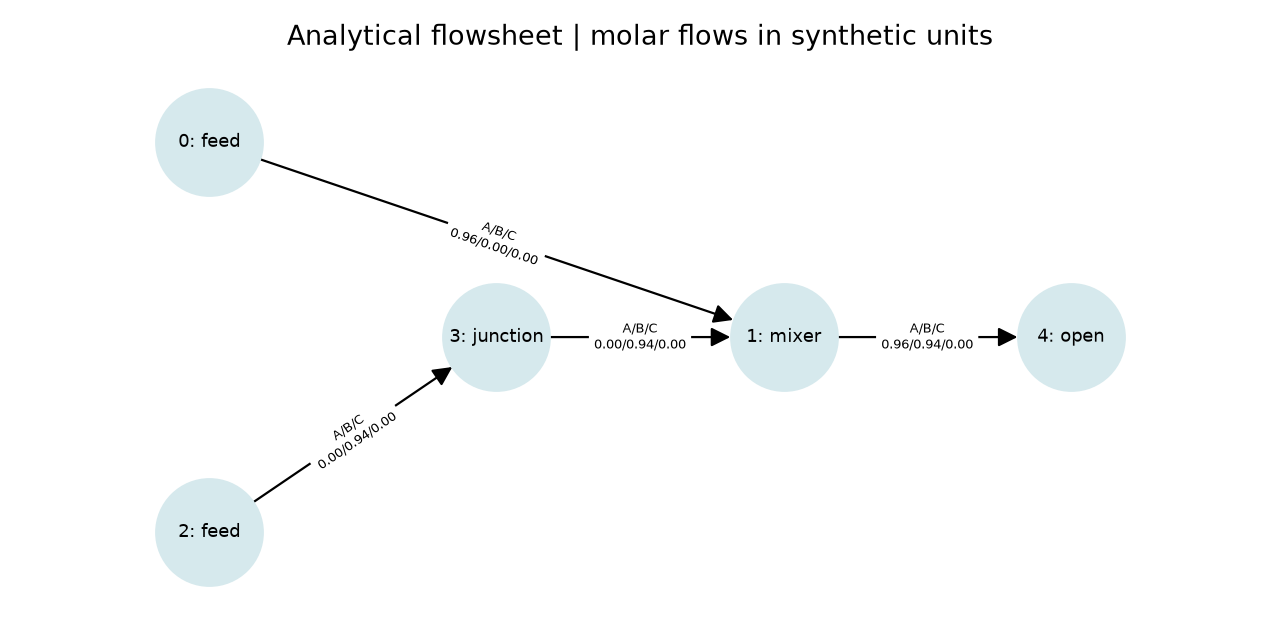

In [13]:
info = apply_and_show(Action(1, Unit.MIXER, partner=3), 'STEP 1 — MIX')

### Step 2: heat the mixed stream to 370 K

The normalized parameter is $p=(370-280)/170$.

STEP 2 — THERMAL
Action: Action(stream=4, unit=<Unit.THERMAL: 1>, parameter=0.5294117647058824, partner=0)
Open nodes before: [4] | after: [5]
Reward: -0.01 | terminal: False | truncated: False
Purity: 0.0 | recovery: 0.0
0: feed -> [1]
1: mixer -> [4]
2: feed -> [3]
3: junction -> [1]
4: thermal -> [5]
5: open -> []


|source|target|A|B|C|temperature_K|
|---|---|---|---|---|---|
|0|1|0.96254|0|0|300|
|1|4|0.96254|0.94486|0|300|
|2|3|0|0.94486|0|300|
|3|1|0|0.94486|0|300|
|4|5|0.96254|0.94486|0|370|

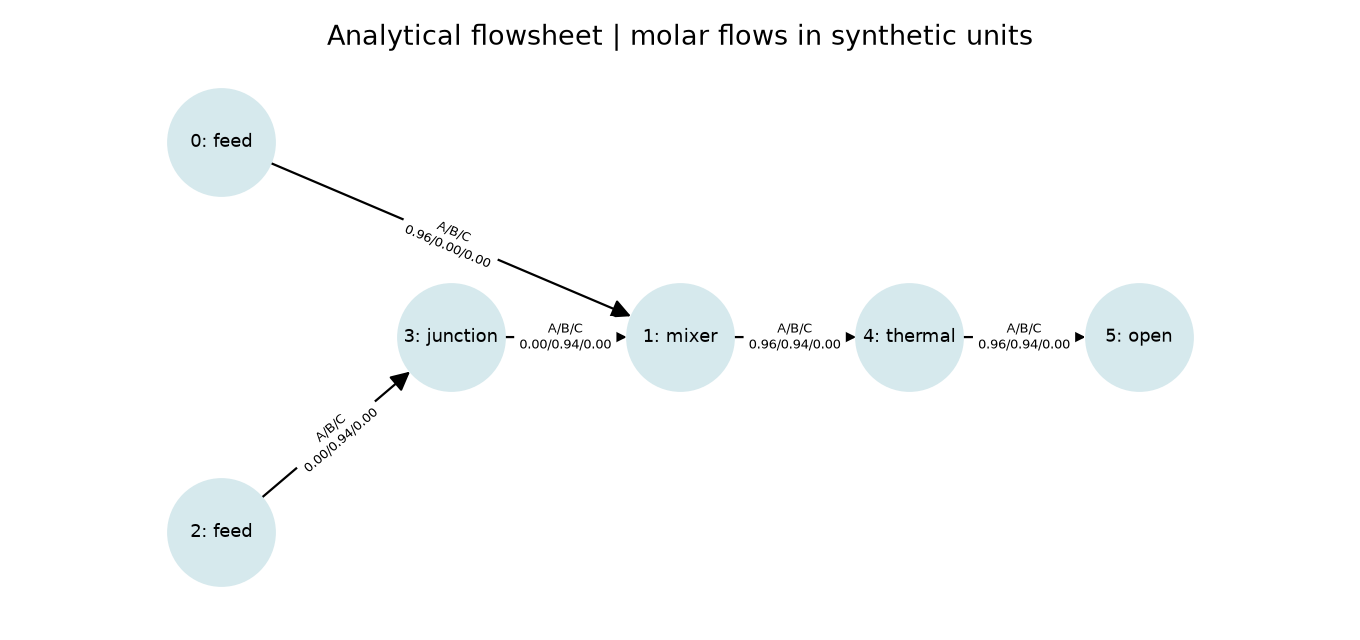

In [14]:
info = apply_and_show(Action(4, Unit.THERMAL, parameter=90/170), 'STEP 2 — THERMAL')

### Step 3: react A and B

STEP 3 — REACTOR
Action: Action(stream=5, unit=<Unit.REACTOR: 2>, parameter=0.85, partner=0)
Open nodes before: [5] | after: [6]
Reward: -0.01 | terminal: False | truncated: False
Purity: 0.0 | recovery: 0.0
0: feed -> [1]
1: mixer -> [4]
2: feed -> [3]
3: junction -> [1]
4: thermal -> [5]
5: reactor -> [6]
6: open -> []


|source|target|A|B|C|temperature_K|
|---|---|---|---|---|---|
|0|1|0.96254|0|0|300|
|1|4|0.96254|0.94486|0|300|
|2|3|0|0.94486|0|300|
|3|1|0|0.94486|0|300|
|4|5|0.96254|0.94486|0|370|
|5|6|0.0499|0.032227|0.91264|370|

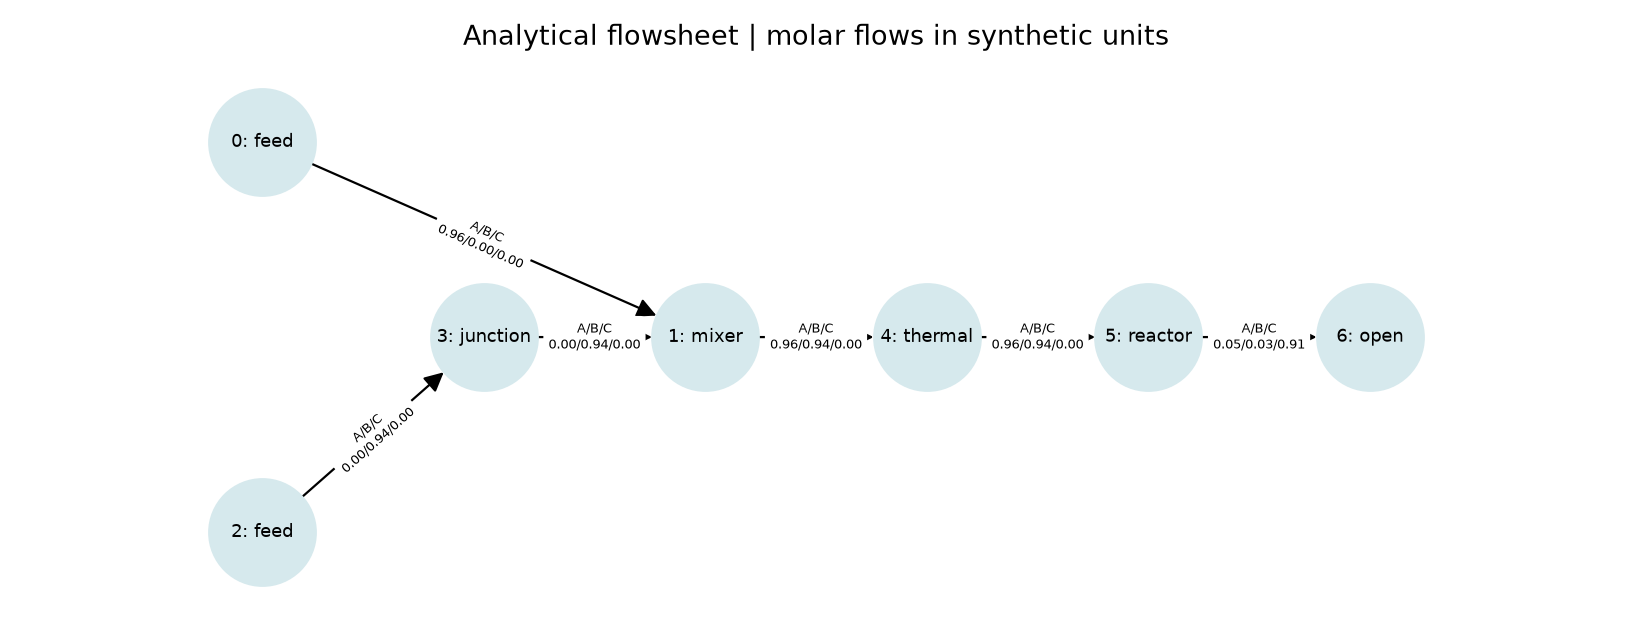

In [15]:
info = apply_and_show(Action(5, Unit.REACTOR, parameter=0.85), 'STEP 3 — REACTOR')

### Step 4: separate a C-rich branch from a residual branch

STEP 4 — SEPARATOR
Action: Action(stream=6, unit=<Unit.SEPARATOR: 3>, parameter=0.9, partner=0)
Open nodes before: [6] | after: [7, 8]
Reward: -0.01 | terminal: False | truncated: False
Purity: 0.0 | recovery: 0.0
0: feed -> [1]
1: mixer -> [4]
2: feed -> [3]
3: junction -> [1]
4: thermal -> [5]
5: reactor -> [6]
6: separator -> [7, 8]
7: open -> []
8: open -> []


|source|target|A|B|C|temperature_K|
|---|---|---|---|---|---|
|0|1|0.96254|0|0|300|
|1|4|0.96254|0.94486|0|300|
|2|3|0|0.94486|0|300|
|3|1|0|0.94486|0|300|
|4|5|0.96254|0.94486|0|370|
|5|6|0.0499|0.032227|0.91264|370|
|6|7|0.0013972|0.00090236|0.86883|370|
|6|8|0.048503|0.031325|0.043807|370|

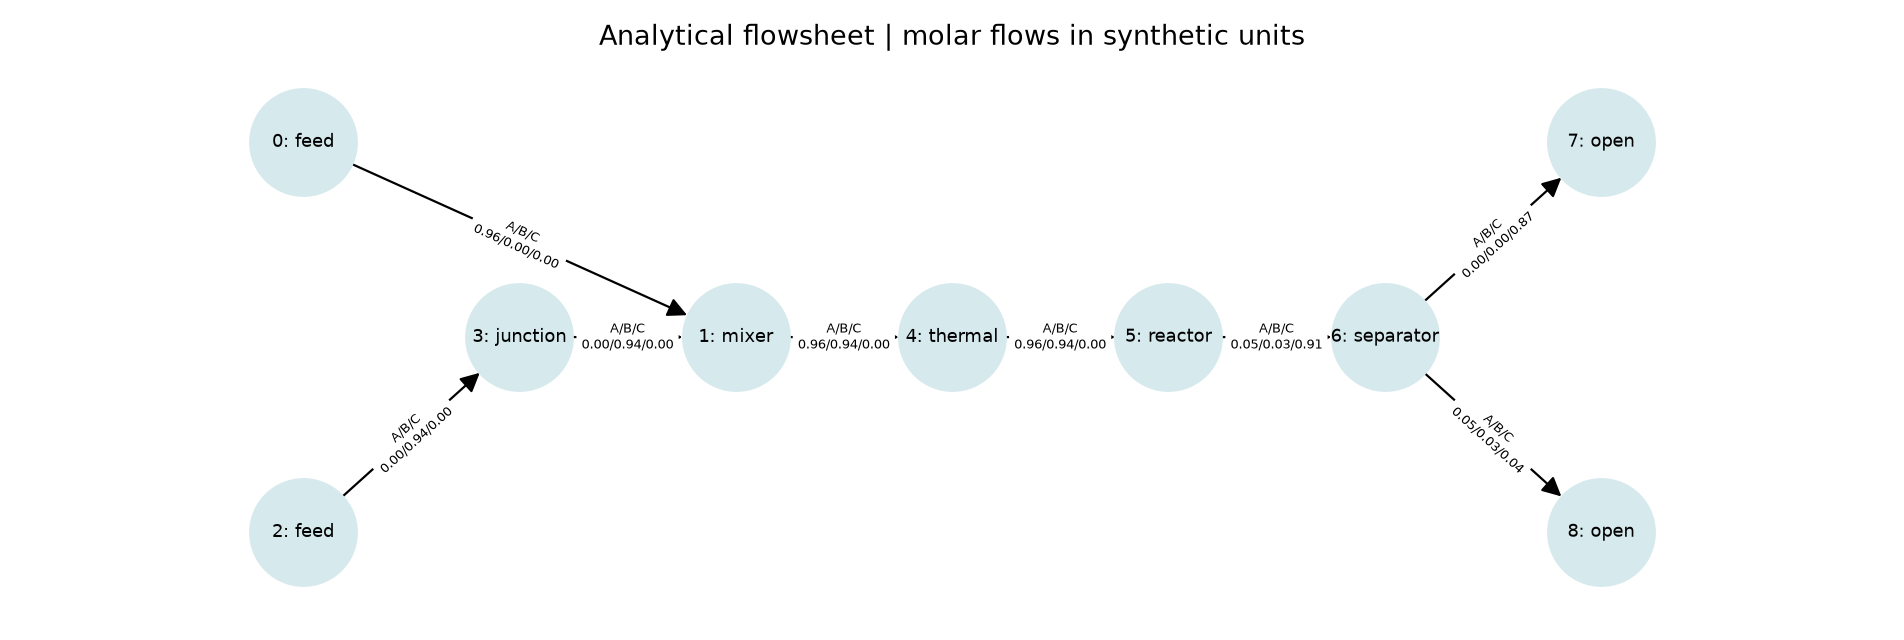

In [16]:
info = apply_and_show(Action(6, Unit.SEPARATOR, parameter=0.9), 'STEP 4 — SEPARATOR')

### Step 5: route the rich branch to product

STEP 5 — PRODUCT
Action: Action(stream=7, unit=<Unit.PRODUCT: 4>, parameter=0.0, partner=0)
Open nodes before: [7, 8] | after: [8]
Reward: -0.01 | terminal: False | truncated: False
Purity: 0.9973602464209581 | recovery: 0.9195293971884632
0: feed -> [1]
1: mixer -> [4]
2: feed -> [3]
3: junction -> [1]
4: thermal -> [5]
5: reactor -> [6]
6: separator -> [7, 8]
7: product -> []
8: open -> []


|source|target|A|B|C|temperature_K|
|---|---|---|---|---|---|
|0|1|0.96254|0|0|300|
|1|4|0.96254|0.94486|0|300|
|2|3|0|0.94486|0|300|
|3|1|0|0.94486|0|300|
|4|5|0.96254|0.94486|0|370|
|5|6|0.0499|0.032227|0.91264|370|
|6|7|0.0013972|0.00090236|0.86883|370|
|6|8|0.048503|0.031325|0.043807|370|

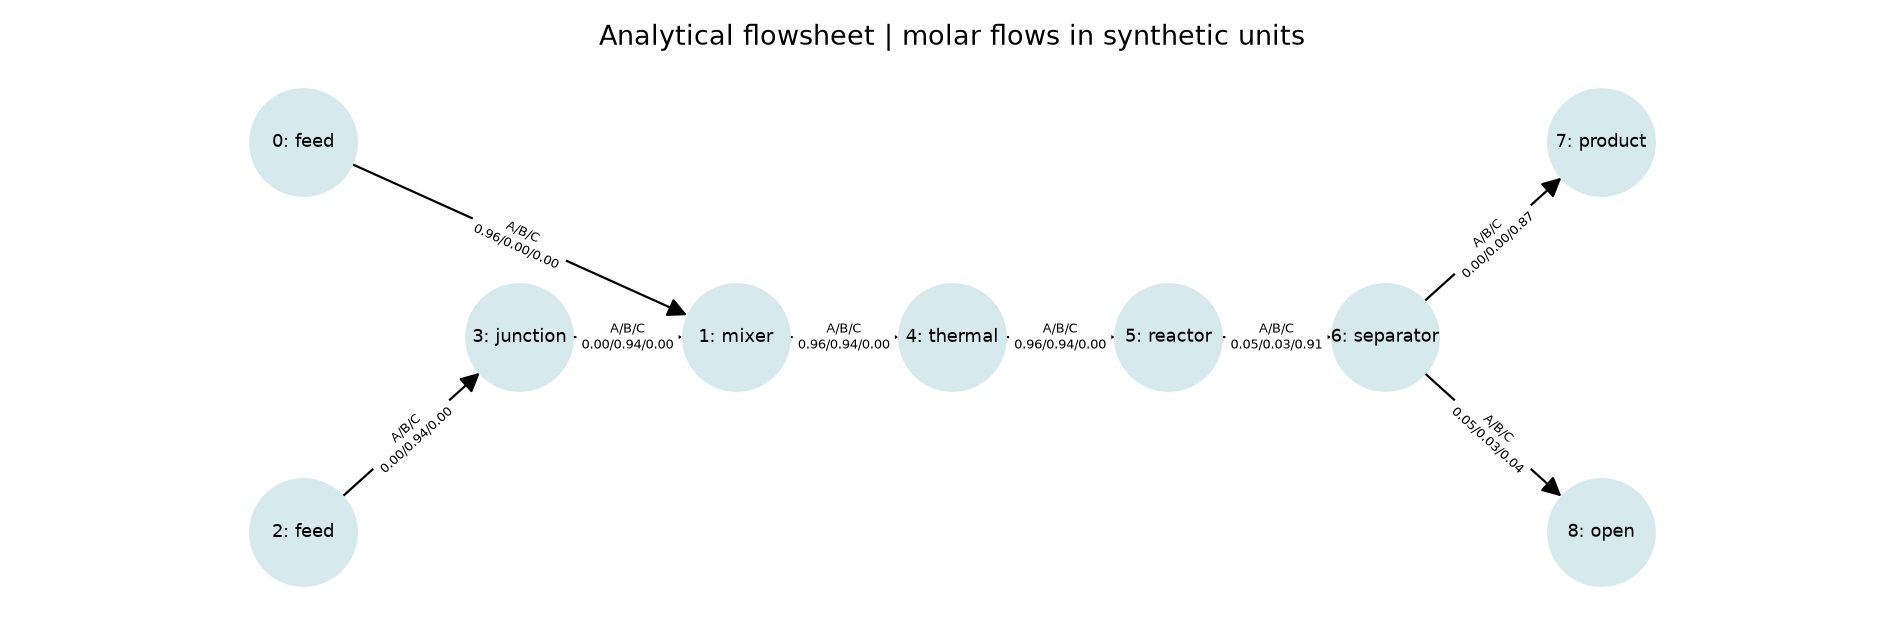

In [17]:
info = apply_and_show(Action(7, Unit.PRODUCT), 'STEP 5 — PRODUCT')

### Step 6: purge the residual and close the flowsheet

STEP 6 — PURGE
Action: Action(stream=8, unit=<Unit.PURGE: 5>, parameter=0.0, partner=0)
Open nodes before: [8] | after: []
Reward: 9.542811426688422 | terminal: True | truncated: False
Purity: 0.9973602464209581 | recovery: 0.9195293971884632
0: feed -> [1]
1: mixer -> [4]
2: feed -> [3]
3: junction -> [1]
4: thermal -> [5]
5: reactor -> [6]
6: separator -> [7, 8]
7: product -> []
8: purge -> []


|source|target|A|B|C|temperature_K|
|---|---|---|---|---|---|
|0|1|0.96254|0|0|300|
|1|4|0.96254|0.94486|0|300|
|2|3|0|0.94486|0|300|
|3|1|0|0.94486|0|300|
|4|5|0.96254|0.94486|0|370|
|5|6|0.0499|0.032227|0.91264|370|
|6|7|0.0013972|0.00090236|0.86883|370|
|6|8|0.048503|0.031325|0.043807|370|

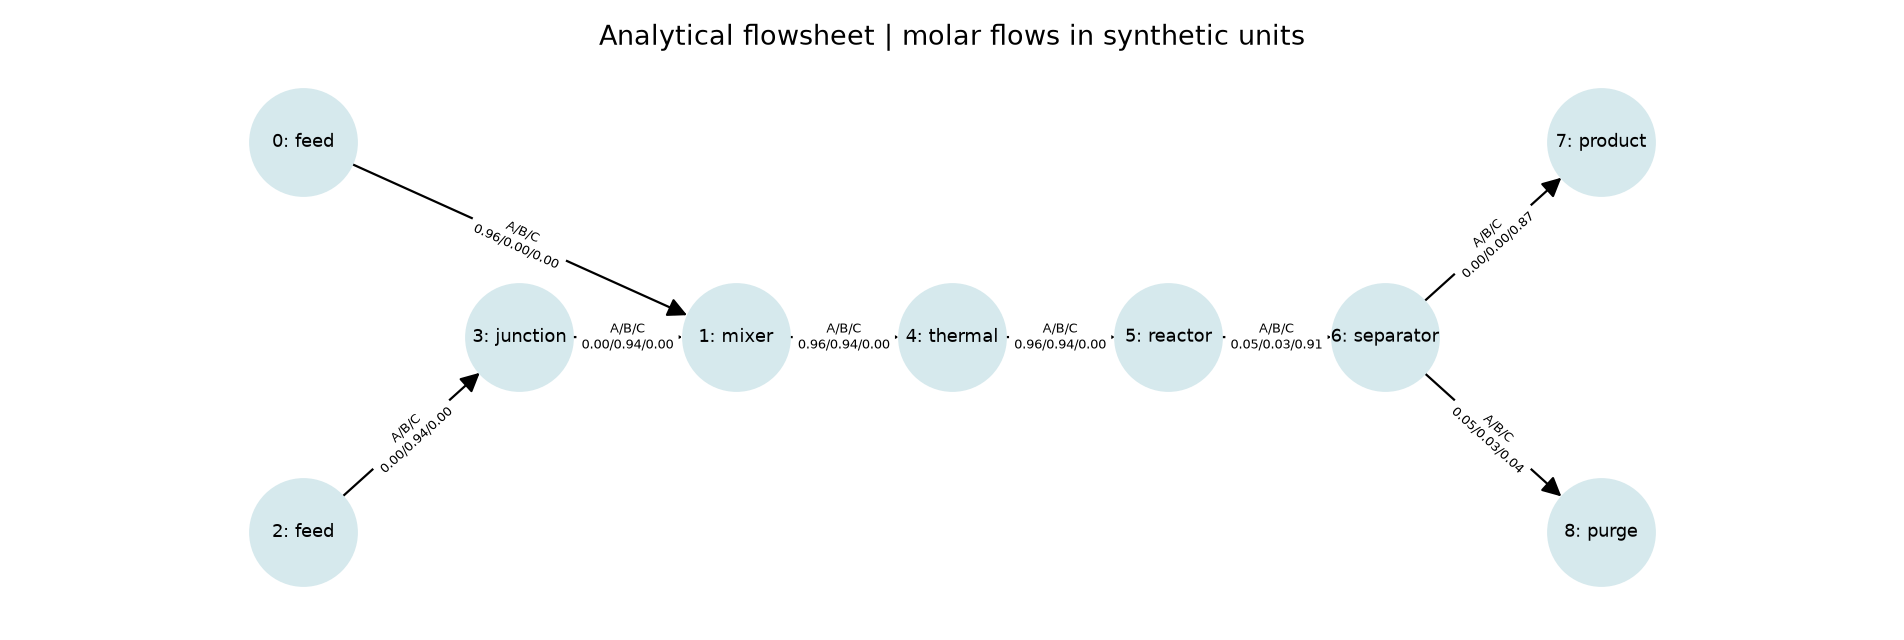

Final feasible: True
Component-balance residual: [0.0, 0.0, 0.0]
Total episode return: 9.492811426688421
Reward decomposition: {'product_value': 9.171020661712006, 'utility': -0.634759235023585, 'capital': -0.78345, 'complexity': -0.2, 'success': 2.0, 'specification': -0.0, 'open_streams': -0.0, 'failure': -0.0, 'step': -0.01}


In [18]:
info = apply_and_show(Action(8, Unit.PURGE), "STEP 6 — PURGE")
print("Final feasible:", info["feasible"])
print("Component-balance residual:", info["component_balance_residual"])
print("Total episode return:", manual_total_return)
print("Reward decomposition:", info["reward_breakdown"])

### What `env.step(action)` did each time

```mermaid
sequenceDiagram
    participant P as Policy or learner
    participant E as FlowsheetEnv
    participant M as Masks and rules
    participant G as Candidate graph
    participant S as Simulator
    participant R as Reward
    P->>E: Action
    E->>M: Validate action
    M-->>E: valid or failure reason
    E->>G: Copy graph and add unit
    E->>S: Simulate candidate
    S-->>E: streams, balances and metrics
    alt simulation succeeds
        E->>E: Commit candidate graph
    else simulation fails
        E->>E: Keep previous valid graph
    end
    E->>R: Score step or final design
    E-->>P: observation, reward, flags, info
```

This copy-simulate-commit pattern is why a failed proposal does not corrupt the last valid state.

### Reveal the graph-edit and environment-step implementations

In [19]:
show_source(FlowsheetGraph.add_unit)
show_source(FlowsheetEnv.step)

def add_unit(self, selected, kind, parameter=0.0, partner=None):
    if selected not in self.open_nodes or kind not in EQUIPMENT + ("product", "purge"):
        raise ValueError("invalid_location_or_unit")
    if kind == "mixer" and (partner not in self.open_nodes or partner == selected):
        raise ValueError("invalid_mixer_partner")
    self.graph.nodes[selected].update(kind=kind, parameter=float(parameter))
    if kind == "mixer":
        # Keep the second boundary as a zero-cost connector, preserving stable IDs.
        self.graph.nodes[partner]["kind"] = "junction"
        self.graph.add_edge(partner, selected, port=0)
    for port in range(2 if kind == "separator" else int(kind in EQUIPMENT)):
        new_id = len(self.graph)
        self.graph.add_node(new_id, kind="open", parameter=0.0)
        self.graph.add_edge(selected, new_id, port=port)
    self.validate()

def step(self, action):
    if self.done:
        raise RuntimeError("reset_required_after_episode")
    failure_reason = None
    if isinstance(action, dict):
        # Validate the complete Gym representation before integer conversion.
        if not self.action_space.contains(action):
            failure_reason = "action_outside_space"
        else:
            action = Action.from_dict(action)
    elif not isinstance(action, Action):
        failure_reason = "unsupported_action_type"
    if failure_reason is None:
        failure_reason = validate_action(action, self.state, self.config)
    if isinstance(action, Action) and action.unit not in CONTINUOUS_UNITS:
        # Inactive parameters have no physical meaning and must not enter features.
        action = Action(action.stream, action.unit, 0.0, action.partner)
    self.state.step += 1
    terminated, truncated = False, False
    reason = "running"
    if failure_reason:
        terminated, reason = True, "invalid_action"
    elif action.stream == self.config.max_nodes:
        terminated, reason = True, "explicit_stop"
    else:
        candidate = self.state.copy()
        candidate.add_unit(
            action.stream, UNIT_NAMES[action.unit], action.parameter, action.partner
        )
        result = self.simulator.simulate(candidate, self.config)
        self.simulator_calls += 1
        if result.calculation_status != "ok":
            self.failed_result = result
            terminated, reason = True, "simulation_failure"
        else:
            self.state, self.result = candidate, result
            if not self.state.open_nodes:
                terminated, reason = True, "all_streams_closed"
    if not terminated and self.state.step >= self.config.max_steps:
        truncated, reason = True, "design_budget"
    self.done = terminated or truncated
    failure = reason in ("invalid_action", "simulation_failure")
    terms = reward_breakdown(
        self.result, self.state, self.config, self.reward_config, self.done, failure
    )
    self.history.append(
        {
            "action": (
                {
                    "stream": action.stream,
                    "unit": action.unit,
                    "parameter": float(action.parameter)
                    if np.isfinite(action.parameter)
                    else None,
                    "partner": action.partner,
                }
                if isinstance(action, Action)
                else None
            ),
            "reward": float(sum(terms.values())),
            "reason": reason,
            "failure_reason": failure_reason,
        }
    )
    return (
        self.observation(),
        float(sum(terms.values())),
        terminated,
        truncated,
        self.info(reason, terms, failure_reason),
    )

## 8. Reward and feasibility are related but not identical

The simulator keeps engineering questions separate: topology validity, numerical completion, physical balance, closure, specification satisfaction and economic proxy. A scalar reward is then built for learning.

At each action there is a $-0.01$ step cost. At episode end:

$$
\begin{aligned}
r_T={}&-0.01+10(\mathrm{recovery})(\mathrm{purity})-0.2Q-0.3C_{capital}-0.05N_{units}\\
&+2\mathbb 1_{feasible}
-4[\max(0,0.90-\mathrm{purity})+\max(0,0.60-\mathrm{recovery})]\\
&-2N_{open}-10\mathbb 1_{failure}.
\end{aligned}
$$

Always inspect feasibility, purity, recovery and balances together with return.

In [20]:
show_source(reward_breakdown)

def reward_breakdown(result, state, config, reward_config, done, failure=False):
    r = reward_config
    terms = {
        name: 0.0
        for name in (
            "product_value",
            "utility",
            "capital",
            "complexity",
            "success",
            "specification",
            "open_streams",
            "failure",
        )
    }
    terms["step"] = -r.step
    if done:
        terms.update(
            product_value=r.product_value * result.product_recovery * result.product_purity,
            utility=-r.utility * result.energy,
            capital=-r.capital * result.capital_cost,
            complexity=-r.complexity * state.num_units,
            success=r.success * float(result.feasible and not failure),
            specification=-r.specification
            * (
                max(0.0, config.purity_min - result.product_purity)
                + max(0.0, config.recovery_min - result.product_recovery)
            ),
            open_streams=-r.open_stream * len(state.open_nodes),
            failure=-r.failure * float(failure),
        )
    return terms

## 9. Convert the flowsheet into tensors for the GNN

In [21]:
final_observation = manual.observation()
data = to_pyg(final_observation)
print("Node feature matrix X:", tuple(data.x.shape))
print("Edge feature matrix Z:", tuple(data.edge_attr.shape))
print("Connectivity edge_index:", tuple(data.edge_index.shape))
print("Global features:", tuple(data.globals.shape))
print("\nFirst three node rows:\n", data.x[:3])
print("\nFirst three stream rows:\n", data.edge_attr[:3])
print("\nDirected connections:\n", data.edge_index)
print("\nGlobal vector:\n", data.globals)

Node feature matrix X: (9, 15)
Edge feature matrix Z: (8, 9)
Connectivity edge_index: (2, 8)
Global features: (1, 9)

First three node rows:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.1176, 1.0000, 0.0000, 0.0000, 1.0000],
        [0.0000, 0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.1176, 1.0000, 0.0000, 0.0000, 1.0000],
        [1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.1176, 1.0000, 0.0000, 0.0000, 1.0000]])

First three stream rows:
 tensor([[0.4813, 1.0000, 0.0000, 0.0000, 0.1176, 1.0000, 0.0000, 0.0000, 1.0000],
        [0.9537, 0.5046, 0.4954, 0.0000, 0.1176, 1.0000, 0.0000, 0.0000, 1.0000],
        [0.4724, 0.0000, 1.0000, 0.0000, 0.1176, 1.0000, 0.0000, 0.0000, 1.0000]])

Directed connections:
 tensor([[0, 1, 2, 3, 4, 5, 6, 6],
        [1, 4, 3, 1, 5, 6, 7, 8]])

Global vector:
 tensor([[0.3750, 0.5000, 0.3174, 0.2612, 0.9974, 0.9195,

The neural observation is

$$s_t=(\mathcal G_t,\mathbf g_t,\mathbf m_t),\qquad
\mathcal G_t=(V_t,E_t,X_t,Z_t).$$

- $X\in\mathbb R^{N\times15}$ contains node type and state features.
- $Z\in\mathbb R^{E\times9}$ contains stream features.
- `edge_index` tells PyG which node sends each message and which node receives it.
- $\mathbf g\in\mathbb R^9$ contains whole-flowsheet features.
- $\mathbf m$ contains stream and unit masks.

NetworkX is convenient for editing the process. PyG tensors are convenient for neural computation. `to_pyg()` is the bridge.

In [22]:
show_source(FlowsheetGraph.graph_instance)
show_source(to_pyg)

def graph_instance(self):
    ids = sorted(self.graph)
    lookup = {n: i for i, n in enumerate(ids)}
    x = []
    for n in ids:
        a = self.graph.nodes[n]
        s = a["stream"]
        one_hot = [float(a["kind"] == kind) for kind in NODE_TYPES]
        x.append(
            one_hot
            + [
                float(a["kind"] == "open"),
                (s.temperature - 280) / 170,
                s.pressure,
                a.get("parameter", 0.0),
                a.get("performance", 0.0),
                1.0,
            ]
        )
    edges, links = [], []
    for source, target, a in sorted(self.graph.edges(data=True)):
        s = a["stream"]
        edges.append(
            [
                s.total / 2,
                *s.composition.tolist(),
                (s.temperature - 280) / 170,
                s.pressure,
                float(self.graph.nodes[target]["kind"] == "open"),
                0.0,
                1.0,
            ]
        )
        links.append([lookup[source], lookup[target]])
    return GraphInstance(
        np.asarray(x, dtype=np.float32),
        np.asarray(edges, dtype=np.float32).reshape(-1, EDGE_DIM),
        np.asarray(links, dtype=np.int64).reshape(-1, 2),
    )

def to_pyg(observation):
    import torch
    from torch_geometric.data import Data

    graph = observation["graph"]
    return Data(
        x=torch.as_tensor(graph.nodes, dtype=torch.float32),
        edge_index=torch.as_tensor(graph.edge_links.T.copy(), dtype=torch.long),
        edge_attr=torch.as_tensor(graph.edges, dtype=torch.float32),
        globals=torch.as_tensor(observation["globals"], dtype=torch.float32).view(1, -1),
    )

## 10. Inspect the GNN and hierarchical action before training

In [23]:
seed_everything(7)
untrained_model = ActorCritic(config.model)
fresh_env = FlowsheetEnv(config.environment, config.reward)
fresh_observation, _ = fresh_env.reset(seed=SEED)
inspection = inspect_decision(untrained_model, fresh_observation)

print("Tensor and embedding shapes:", json.dumps(inspection["shapes"], indent=2))
print("Greedy untrained action:", inspection["action"])
print("Stream probabilities:", inspection["distributions"]["stream_probabilities"])
print("Critic value:", inspection["value"])
print("One edge message example:", json.dumps(inspection["message_example"], indent=2))

Tensor and embedding shapes: {
  "nodes": [
    4,
    15
  ],
  "edges": [
    2,
    9
  ],
  "edge_index": [
    2,
    2
  ],
  "global_features": [
    1,
    9
  ],
  "node_embeddings": [
    4,
    32
  ],
  "graph_embedding": [
    1,
    32
  ]
}
Greedy untrained action: {'stream': 20, 'unit': 5, 'parameter': 0.0, 'partner': 0}
Stream probabilities: [0.0, 0.25252753496170044, 0.0, 0.2531683146953583, 0.4943041205406189]
Critic value: 0.2008788138628006
One edge message example: {
  "edge": [
    0,
    1
  ],
  "initial_source_first4": [
    0.10795393586158752,
    -0.022534949705004692,
    0.29882052540779114,
    -0.09903376549482346
  ],
  "first_message_first4": [
    -0.13246756792068481,
    0.07380945980548859,
    -0.03236246109008789,
    -0.12312965840101242
  ],
  "receiver_updated_first4": [
    -0.07357756048440933,
    0.9607089161872864,
    0.4997985363006592,
    -1.5836113691329956
  ],
  "message_norm": 0.6524612307548523
}


For an edge $u\rightarrow v$, the GNN calculates a message

$$m_{u\rightarrow v}=\operatorname{MLP}([h_u,z_{u\rightarrow v}]),$$

sums incoming messages, and updates the receiver. After two layers, node embeddings are summed and combined with global features to make a flowsheet embedding.

The actor then chooses conditionally:

$$\pi(a|s)=\pi_{stream}\pi_{unit}\pi_{parameter\;or\;partner}.$$

The critic reads the flowsheet embedding and predicts expected future discounted reward. Before training, all these neural weights are random.

### Reveal the GNN forward pass and policy distribution construction

In [24]:
show_source(DirectedLayer)
show_source(GNNEncoder.forward)
show_source(ActorCritic._distributions)
show_source(ActorCritic._output)

class DirectedLayer(MessagePassing):
    def __init__(self, hidden):
        super().__init__(aggr="add", flow="source_to_target")
        self.message_net = nn.Sequential(
            nn.Linear(hidden + EDGE_DIM, hidden), nn.SiLU(), nn.Linear(hidden, hidden)
        )
        self.self_net = nn.Linear(hidden, hidden)
        self.norm = nn.LayerNorm(hidden)

    def forward(self, h, edge_index, edge_attr):
        incoming = self.propagate(edge_index, x=h, edge_attr=edge_attr)
        return self.norm(h + torch.nn.functional.silu(self.self_net(h) + incoming))

    def message(self, x_j, edge_attr):
        return self.message_net(torch.cat([x_j, edge_attr], dim=-1))

def forward(self, data):
    h = torch.nn.functional.silu(self.input(data.x))
    for layer in self.layers:
        h = layer(h, data.edge_index, data.edge_attr)
    batch = getattr(data, "batch", None)
    if batch is None:
        batch = torch.zeros(h.size(0), dtype=torch.long, device=h.device)
    pooled = global_add_pool(h, batch)
    return h, self.readout(torch.cat([pooled, data.globals], dim=-1))

def _distributions(self, observation, nodes, graph):
    n = nodes.shape[0]
    contexts = torch.cat([nodes, graph.expand(n, -1)], dim=-1)
    stream_logits = torch.cat(
        [self.stream_head(contexts).squeeze(-1), self.stop_head(graph).reshape(1)]
    )
    mask = torch.as_tensor(observation["stream_mask"], device=self.device, dtype=torch.bool)
    stream = masked_categorical(stream_logits, torch.cat([mask[:n], mask[-1:]]))
    open_ids = mask[:n].nonzero().flatten().tolist()
    units, parameters, partners = {}, {}, {}
    for index in open_ids:
        units[index] = masked_categorical(
            self.unit_head(contexts[index]), observation["unit_mask"][index]
        )
        parameters[index] = {
            unit: beta_distribution(self.parameter_heads[str(int(unit))](contexts[index]))
            for unit in CONTINUOUS_UNITS
        }
        if bool(observation["unit_mask"][index, Unit.MIXER]):
            partner_context = torch.cat([contexts[index].expand(n, -1), nodes], dim=-1)
            partner_mask = mask[:n].clone()
            partner_mask[index] = False
            partners[index] = masked_categorical(
                self.partner_head(partner_context).squeeze(-1), partner_mask
            )
    # Chain rule H(S,U,P)=H(S)+sum_s p(s)[H(U|s)+sum_u p(u|s)H(P|s,u)].
    # STOP has no descendants. Mixer has a discrete partner instead of a parameter.
    entropy = stream.entropy()
    for index in open_ids:
        conditional = units[index].entropy()
        for unit in CONTINUOUS_UNITS:
            conditional = (
                conditional + units[index].probs[unit] * parameters[index][unit].entropy()
            )
        if index in partners:
            conditional = (
                conditional + units[index].probs[Unit.MIXER] * partners[index].entropy()
            )
        entropy = entropy + stream.probs[index] * conditional
    return stream, units, parameters, partners, entropy

def _output(self, observation, nodes, graph, action=None, deterministic=False):
    stream, units, params, partners, entropy = self._distributions(observation, nodes, graph)
    stop = len(observation["stream_mask"]) - 1
    n = nodes.shape[0]
    choose = lambda dist: dist.probs.argmax() if deterministic else dist.sample()
    if action is None:
        selected = int(choose(stream))
        if selected == n:
            action = Action(stop)
        else:
            unit = int(choose(units[selected]))
            parameter, partner = 0.0, 0
            if unit in CONTINUOUS_UNITS:
                distribution = params[selected][unit]
                parameter = float(distribution.mean if deterministic else distribution.sample())
            if unit == Unit.MIXER:
                partner = int(choose(partners[selected]))
            action = Action(selected, unit, parameter, partner)
    selected = n if action.stream == stop else action.stream
    components = {"stream": stream.log_prob(torch.tensor(selected, device=self.device))}
    diagnostics = {"stream_probabilities": stream.probs}
    if selected != n:
        unit_distribution = units[selected]
        components["unit"] = unit_distribution.log_prob(
            torch.tensor(action.unit, device=self.device)
        )
        diagnostics["unit_probabilities"] = unit_distribution.probs
        if action.unit in CONTINUOUS_UNITS:
            if not 0 < action.parameter < 1:
                raise ValueError("Beta likelihood requires an interior parameter")
            distribution = params[selected][action.unit]
            components["parameter"] = distribution.log_prob(
                torch.tensor(action.parameter, device=self.device)
            )
            diagnostics.update(
                alpha=distribution.concentration1, beta=distribution.concentration0
            )
        if action.unit == Unit.MIXER:
            components["partner"] = partners[selected].log_prob(
                torch.tensor(action.partner, device=self.device)
            )
    log_prob = torch.stack(list(components.values())).sum()
    return PolicyOutput(
        action,
        components,
        log_prob,
        entropy,
        self.critic(graph).squeeze(),
        {k: observation[k] for k in ("stream_mask", "unit_mask")},
        diagnostics,
    )

## 11. Evaluate untrained, random and rule policies on identical feeds

In [25]:
evaluation_seeds = [101, 102, 103, 104, 105]
comparison = []
for policy, name in [
    ("random", "random valid"),
    ("rule", "engineering rule"),
    (untrained_model, "untrained neural"),
]:
    rows, summary = evaluate_policy(policy, config, evaluation_seeds, name)
    comparison.append({
        "policy": name,
        "return_mean": summary["return_mean"],
        "feasible_rate": summary["feasible_rate"],
        "purity_mean": summary["product_purity_mean"],
        "recovery_mean": summary["product_recovery_mean"],
    })
show_records(comparison, ["policy", "return_mean", "feasible_rate", "purity_mean", "recovery_mean"])

|policy|return_mean|feasible_rate|purity_mean|recovery_mean|
|---|---|---|---|---|
|random valid|-8.9774|0|0|0|
|engineering rule|9.4355|1|0.99595|0.91953|
|untrained neural|-10.01|0|0|0|

The rule policy is a reachability check: it demonstrates that the custom simulator and action space permit a feasible route. The untrained neural policy is a random-weight reference. Neither comparison proves that RL is superior; it gives us a starting point.

## 12. How learning data are collected

In [26]:
show_source(Collector.collect)
show_source(generalized_advantages)

@torch.no_grad()
def collect(self, model, count, gamma, lam):
    observations, actions, logs = [], [], []
    rewards, values, next_values, bootstraps, ends, episodes = [], [], [], [], [], []
    model.eval()
    for _ in range(count):
        out = model(self.observation)
        next_observation, reward, terminated, truncated, info = self.env.step(out.action)
        done = terminated or truncated
        observations.append(self.observation)
        actions.append(out.action)
        logs.append(float(out.log_prob))
        rewards.append(reward)
        values.append(float(out.value))
        bootstrap = info["bootstrap_allowed"]
        next_values.append(float(model.value(next_observation)) if bootstrap else 0.0)
        bootstraps.append(bootstrap)
        ends.append(done)
        self.episode_return += reward
        self.total_steps += 1
        self.observation = next_observation
        if done:
            self.total_episodes += 1
            episodes.append(
                {
                    "episode": self.total_episodes,
                    "steps": self.total_steps,
                    "return": self.episode_return,
                    "feasible": info["feasible"],
                    "termination_reason": info["termination_reason"],
                    **{
                        k: info[k]
                        for k in (
                            "product_purity",
                            "product_recovery",
                            "energy",
                            "capital_cost",
                            "num_units",
                            "simulator_calls",
                        )
                    },
                }
            )
            if info["feasible"] and self.first_feasible_step is None:
                self.first_feasible_step = self.total_steps
                self.first_feasible_episode = self.total_episodes
            self.observation, _ = self.env.reset()
            self.episode_return = 0.0
    advantages, returns = generalized_advantages(
        rewards, values, next_values, bootstraps, ends, gamma, lam
    )
    return Rollout(observations, actions, logs, advantages, returns, episodes)

def generalized_advantages(
    rewards, values, next_values, bootstrap, episode_ends, gamma=0.99, lam=0.95
):
    """Separate value bootstrap from recursion across independent episodes."""
    rewards, values, next_values = (
        np.asarray(x, dtype=np.float64) for x in (rewards, values, next_values)
    )
    bootstrap, episode_ends = np.asarray(bootstrap), np.asarray(episode_ends)
    deltas = rewards + gamma * next_values * bootstrap - values
    advantages = np.zeros_like(deltas)
    running = 0.0
    for t in reversed(range(len(rewards))):
        running = deltas[t] + gamma * lam * (not episode_ends[t]) * running
        advantages[t] = running
    return advantages.astype(np.float32), (advantages + values).astype(np.float32)

For every transition the collector stores the observation, sampled action, old joint log-probability, reward and critic value. Generalized Advantage Estimation computes

$$\delta_t=r_t+\gamma b_tV(s_{t+1})-V(s_t),$$

$$A_t=\delta_t+\gamma\lambda(1-d_t)A_{t+1}.$$

$A_t>0$ means the result was better than the critic expected. $A_t<0$ means it was worse. Episode flags stop information from leaking from one flowsheet into the next.

In [27]:
# Tiny numerical GAE example: three transitions ending an episode.
rewards = [-0.01, -0.01, 5.0]
values = [0.2, 0.4, 1.0]
next_values = [0.4, 1.0, 0.0]
bootstrap = [True, True, False]
episode_ends = [False, False, True]
advantages, value_targets = generalized_advantages(
    rewards, values, next_values, bootstrap, episode_ends, gamma=0.99, lam=0.95
)
print("Advantages:", advantages)
print("Value targets:", value_targets)

Advantages: [4.269651 4.342    4.      ]
Value targets: [4.469651 4.742    5.      ]


## 13. Where PPO changes the neural weights

PPO compares the current probability with the stored old probability:

$$\rho_t=\exp(\log\pi_{new}(a_t|s_t)-\log\pi_{old}(a_t|s_t)).$$

The clipped actor objective limits large policy changes. The total loss combines actor loss, squared critic error and an entropy term. `loss.backward()` calculates gradients through the GNN, actor and critic. `optimizer.step()` changes their weights. No gradient passes through the process simulator.

In [28]:
# Exact section of ppo.py that shuffles minibatches, forms the loss and updates weights.
show_file_lines("src/flowsheet_rl/training/ppo.py", 154, 207)

154          episodes.extend(rollout.episodes)
 155          adv = torch.as_tensor(rollout.advantages, device=model.device)
 156          adv = (adv - adv.mean()) / (adv.std(unbiased=False) + 1e-8)
 157          returns = torch.as_tensor(rollout.returns, device=model.device)
 158          old_logs = torch.tensor(rollout.log_probs, dtype=torch.float32, device=model.device)
 159          model.train()
 160          losses, norms, kls, clipped, entropies, actors, critics = [], [], [], [], [], [], []
 161          for _ in range(cfg.epochs):
 162              indices = rng.permutation(cfg.rollout_steps)
 163              for begin in range(0, cfg.rollout_steps, cfg.minibatch_size):
 164                  batch = indices[begin : begin + cfg.minibatch_size]
 165                  log_probs, entropy, values = model.evaluate_actions(
 166                      [rollout.observations[i] for i in batch], [rollout.actions[i] for i in batch]
 167                  )
 168                  ratio = torch.exp(log_probs - old_logs[batch])
 169                  objective = torch.minimum(
 170                      ratio * adv[batch],
 171                      ratio.clamp(1 - cfg.clip_ratio, 1 + cfg.clip_ratio) * adv[batch],
 172                  )
 173                  actor_loss = -objective.mean()
 174                  critic_loss = (values - returns[batch]).square().mean()
 175                  loss = actor_loss + cfg.value_coef * critic_loss - cfg.entropy_coef * entropy.mean()
 176                  if not torch.isfinite(loss):
 177                      raise FloatingPointError("nonfinite_ppo_loss")
 178                  optimizer.zero_grad(set_to_none=True)
 179                  loss.backward()
 180                  norm = torch.nn.utils.clip_grad_norm_(
 181                      model.parameters(), cfg.max_grad_norm, error_if_nonfinite=True
 182                  )
 183                  optimizer.step()
 184                  with torch.no_grad():
 185                      losses.append(float(loss))
 186                      actors.append(float(actor_loss))
 187                      critics.append(float(critic_loss))
 188                      norms.append(float(norm))
 189                      entropies.append(float(entropy.mean()))
 190                      kls.append(float(((ratio - 1) - (log_probs - old_logs[batch])).mean()))
 191                      clipped.append(float(((ratio - 1).abs() > cfg.clip_ratio).float().mean()))
 192          entry = {
 193              "update": update + 1,
 194              "steps": collector.total_steps,
 195              "episodes": collector.total_episodes,
 196              "loss": float(np.mean(losses)),
 197              "actor_loss": float(np.mean(actors)),
 198              "critic_loss": float(np.mean(critics)),
 199              "gradient_norm": float(np.mean(norms)),
 200              "entropy": float(np.mean(entropies)),
 201              "approx_kl": float(np.mean(kls)),
 202              "clip_fraction": float(np.mean(clipped)),
 203              "encoder_frozen": update < cfg.freeze_encoder_updates,
 204              "elapsed_seconds": elapsed_before + time.perf_counter() - start,
 205          }
 206          history.append(entry)
 207          if (update + 1) % cfg.evaluation_interval == 0 or update + 1 == cfg.updates:

## 14. Run a small learning demonstration

This demonstration uses the same `train()` function as the long run, with a smaller budget:

$$6\text{ updates}\times128\text{ transitions}=768\text{ transitions}.$$

It is large enough to show that parameters and periodic evaluation can change, but it is not a convergence study. Set `RUN_MINI_TRAINING=False` when you only want to inspect the earlier sections.

In [29]:
RUN_MINI_TRAINING = True
mini_model = None
mini_record = None

if RUN_MINI_TRAINING:
    mini_config = deepcopy(config)
    mini_config.train = TrainConfig(
        seed=7,
        updates=6,
        rollout_steps=128,
        epochs=2,
        minibatch_size=32,
        checkpoint_interval=3,
        evaluation_interval=1,
    )
    mini_dir = session/("mini_training_" + uuid.uuid4().hex[:6])
    begin_experiment(mini_dir, mini_config, "extended_notebook_mini_training")
    mini_model, mini_record = train(
        mini_config,
        mini_dir,
        evaluation_seeds=evaluation_seeds,
        verbose=True,
    )
    print(json.dumps(mini_record["summary"], indent=2))
    print("Checkpoint:", mini_dir/"checkpoint.pt")
else:
    print("Mini training skipped.")

update 1/6 | steps=128 | episodes=79 | loss=39.7171 | first_feasible_step=None
update 2/6 | steps=256 | episodes=143 | loss=30.4065 | first_feasible_step=None
update 3/6 | steps=384 | episodes=201 | loss=26.6200 | first_feasible_step=266
update 4/6 | steps=512 | episodes=254 | loss=20.4955 | first_feasible_step=266
update 5/6 | steps=640 | episodes=302 | loss=17.6629 | first_feasible_step=266
update 6/6 | steps=768 | episodes=357 | loss=13.4374 | first_feasible_step=266
{
  "steps": 768,
  "episodes": 357,
  "parameter_delta_l2": 1.1665563583374023,
  "first_feasible_step": 266,
  "first_feasible_episode": 147,
  "elapsed_seconds": 28.65002539998386
}
Checkpoint: <original-runs>\notebook_sessions\20260928_191526_learning_1a731e\mini_training_430885\checkpoint.pt


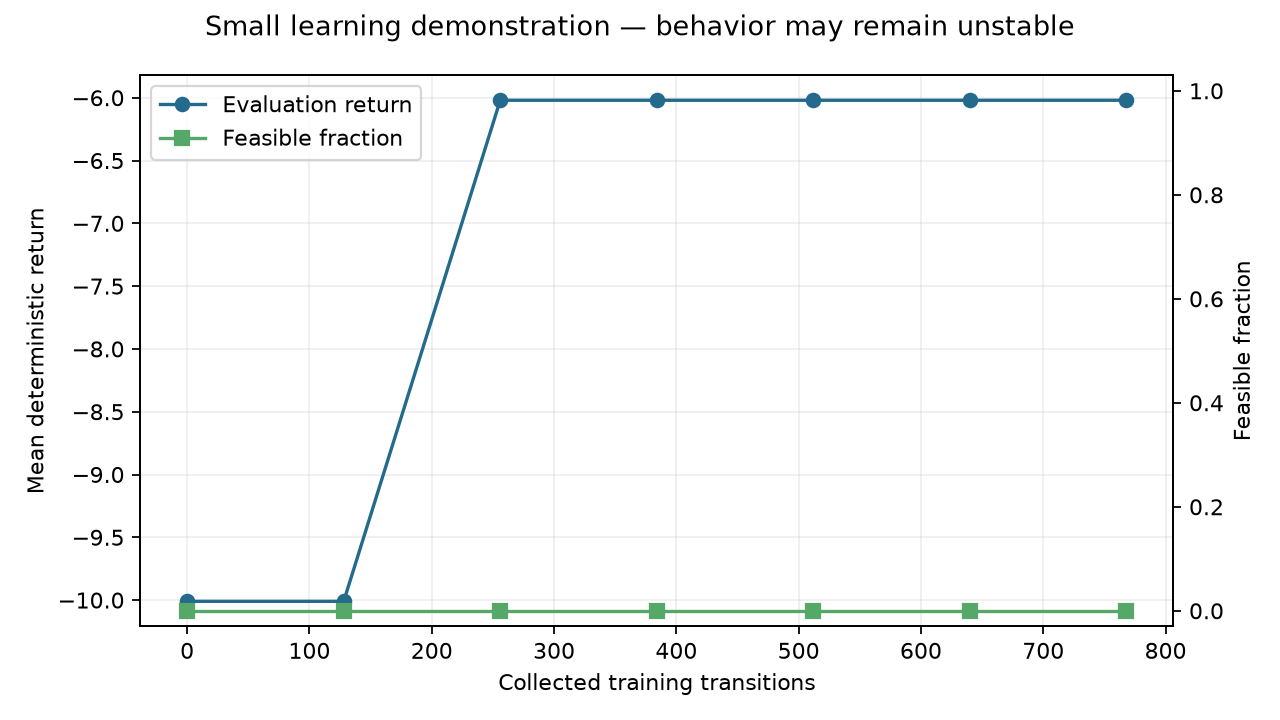

In [30]:
if mini_record is not None:
    curve = mini_record["learning_curve"]
    steps = [point["training_steps"] for point in curve]
    returns = [point["return_mean"] for point in curve]
    feasible = [point["feasible_rate"] for point in curve]
    fig, left = plt.subplots(figsize=(8, 4.5))
    left.plot(steps, returns, marker="o", color="#246a8d", label="Evaluation return")
    left.set_xlabel("Collected training transitions")
    left.set_ylabel("Mean deterministic return")
    right = left.twinx()
    right.plot(steps, feasible, marker="s", color="#55a868", label="Feasible fraction")
    right.set_ylabel("Feasible fraction")
    right.set_ylim(-0.03, 1.03)
    left.grid(alpha=0.2)
    lines = left.lines + right.lines
    left.legend(lines, [line.get_label() for line in lines], loc="best")
    fig.suptitle("Small learning demonstration — behavior may remain unstable")
    fig.tight_layout()
    mini_plot = session/"mini_learning_curve.png"
    fig.savefig(mini_plot, dpi=160)
    plt.close(fig)
    display(Image(filename=str(mini_plot)))

In [31]:
if mini_model is not None:
    mini_rows, mini_summary = evaluate_policy(
        mini_model, mini_config, evaluation_seeds, "mini-trained", mini_dir/"evaluation"
    )
    before_after = [
        comparison[2],
        {
            "policy": "mini-trained",
            "return_mean": mini_summary["return_mean"],
            "feasible_rate": mini_summary["feasible_rate"],
            "purity_mean": mini_summary["product_purity_mean"],
            "recovery_mean": mini_summary["product_recovery_mean"],
        },
    ]
    show_records(before_after, ["policy", "return_mean", "feasible_rate", "purity_mean", "recovery_mean"])

|policy|return_mean|feasible_rate|purity_mean|recovery_mean|
|---|---|---|---|---|
|untrained neural|-10.01|0|0|0|
|mini-trained|-6.02|0|0|0|

The mini run demonstrates execution and parameter change. It may or may not discover a feasible design because 768 transitions are a small sample. That uncertainty is itself an important lesson: a functioning RL loop is not the same as a converged policy.

## 15. Inspect the completed long run without retraining it

In [32]:
import csv

LONG_RUN = PROJECT/"examples"/"long_run"
long_summary = json.loads((LONG_RUN/"evaluation"/"summary.json").read_text(encoding="utf-8"))
with (LONG_RUN/"evaluation"/"episodes.csv").open(encoding="utf-8", newline="") as handle:
    long_rows = list(csv.DictReader(handle))

stages = [
    comparison[2],
    {
        "policy": "recorded-long-run",
        "return_mean": long_summary["return_mean"],
        "feasible_rate": long_summary["feasible_rate"],
        "purity_mean": long_summary["product_purity_mean"],
        "recovery_mean": long_summary["product_recovery_mean"],
    },
    comparison[1],
]
show_records(stages, ["policy", "return_mean", "feasible_rate", "purity_mean", "recovery_mean"])
print("The mini repository retains summaries and plots; run configs/train_long.yaml to create a fresh checkpoint.")

|policy|return_mean|feasible_rate|purity_mean|recovery_mean|
|---|---|---|---|---|
|untrained neural|-10.01|0|0|0|
|long-trained|9.2452|0.8|0.93503|0.9974|
|engineering rule|9.4355|1|0.99595|0.91953|

Per-feed final evaluation:


|seed|return|feasible|product_purity|product_recovery|energy|num_units|
|---|---|---|---|---|---|---|
|101|7.1391|False|0.88932|0.998|2.5849|4|
|102|9.4366|True|0.9108|0.99689|2.3316|4|
|103|10.1|True|0.97682|0.99752|2.3349|4|
|104|9.9623|True|0.96792|0.99757|2.5845|4|
|105|9.5877|True|0.93029|0.99702|2.5544|4|

**training_overview.png**

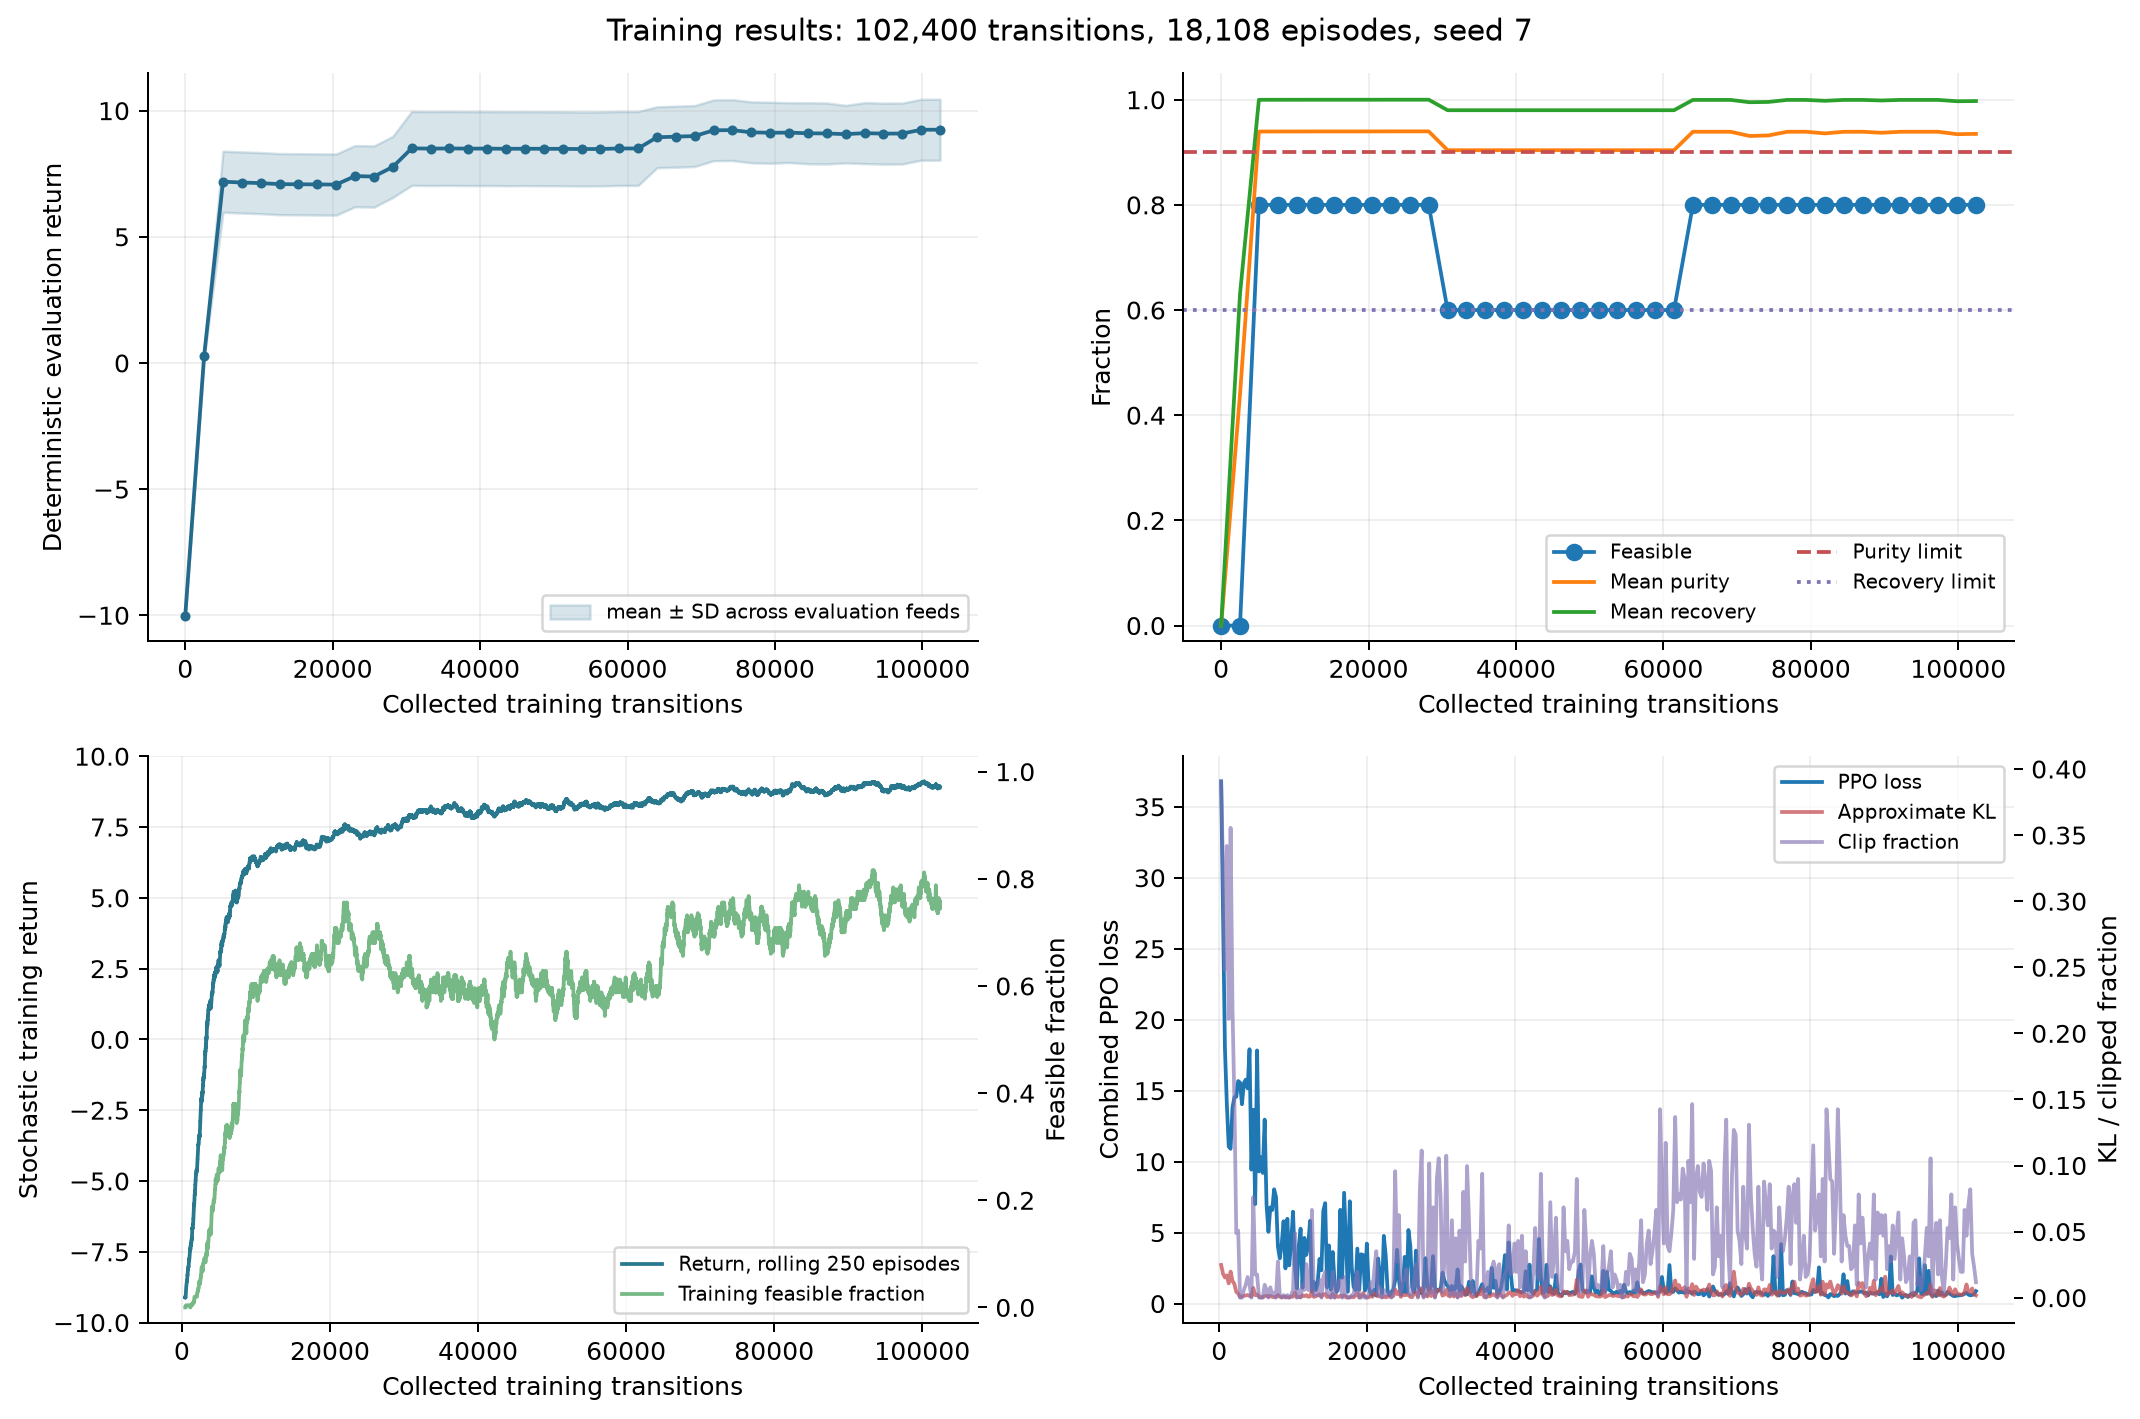

**evaluation_by_seed.png**

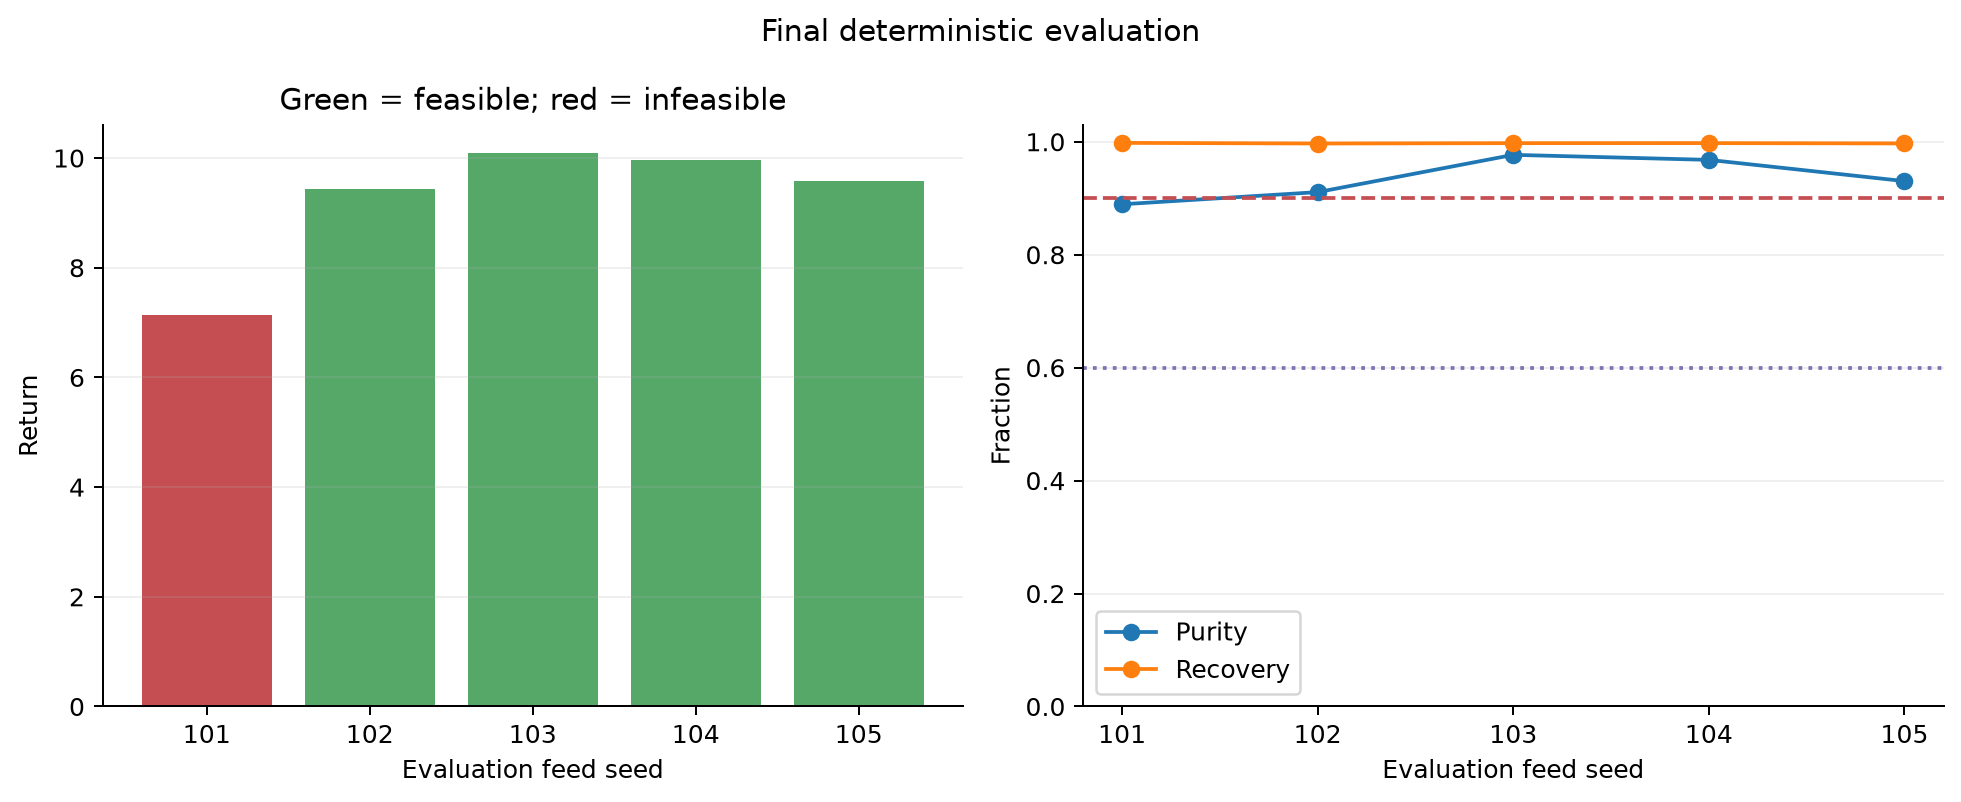

**best_design.png**

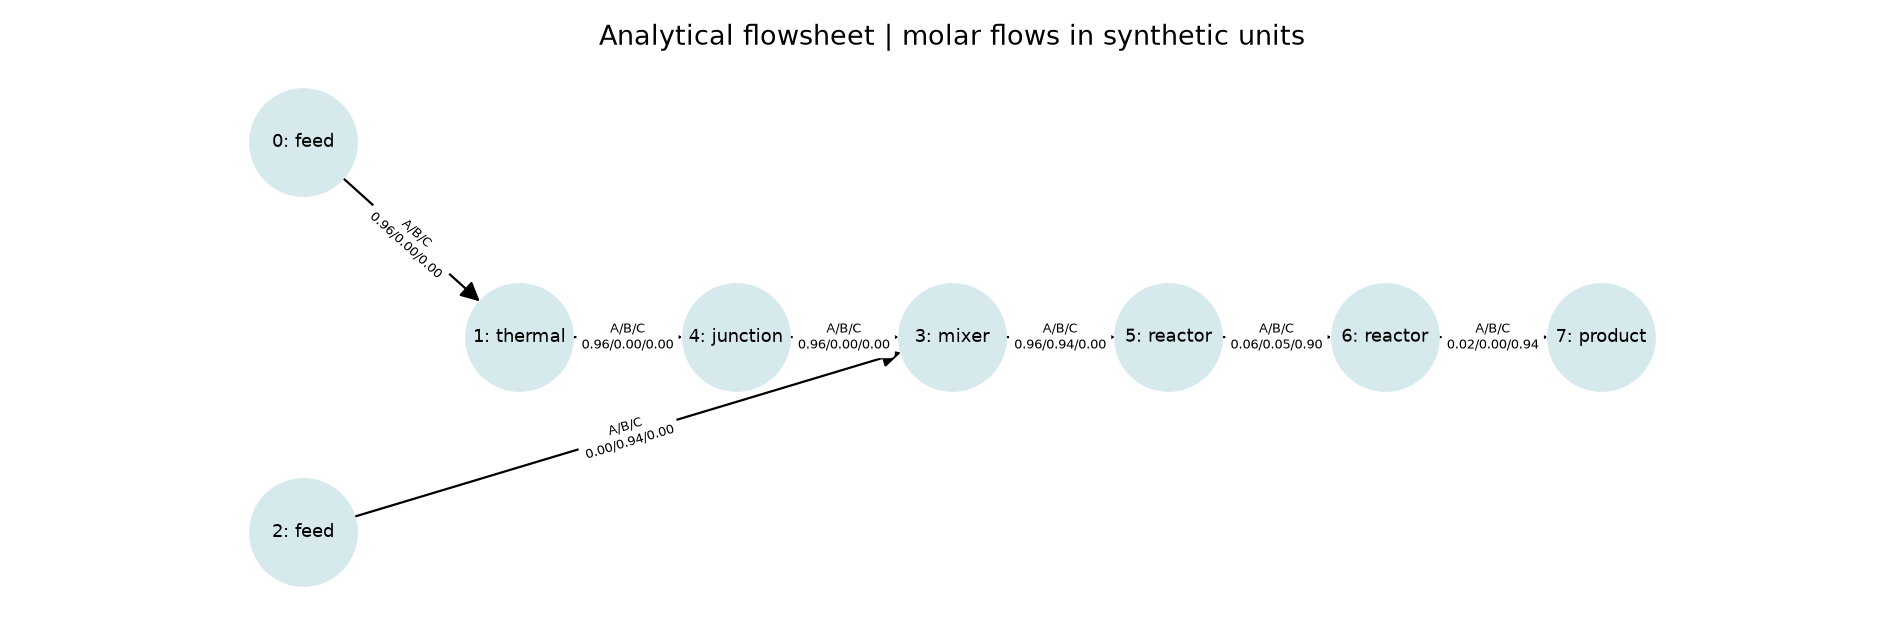

In [33]:
print("Per-feed final evaluation:")
show_records(long_rows, ["seed", "return", "feasible", "product_purity", "product_recovery", "energy", "num_units"])

for image_path in [
    LONG_RUN/"plots"/"training_overview.png",
    LONG_RUN/"plots"/"evaluation_by_seed.png",
    LONG_RUN/"evaluation"/"best_design.png",
]:
    if image_path.exists():
        display(Markdown(f"**{image_path.name}**"))
        display(Image(filename=str(image_path)))

The long checkpoint is evaluated here, not trained again. It provides a visible contrast with the untrained policy and the small demonstration. Its 4/5 final feasible feed cases are encouraging for this synthetic task, but one training seed is not enough to establish repeatability.

## 16. Trace one long-trained episode action by action

|step|stream|unit|parameter|critic_before|reward|purity_after|recovery_after|reason|
|---|---|---|---|---|---|---|---|---|
|1|1|thermal|0.81536|8.4115|-0.01|0|0|running|
|2|3|mixer|0|8.5567|-0.01|0|0|running|
|3|5|reactor|0.85957|8.7006|-0.01|0|0|running|
|4|6|reactor|0.85402|8.8354|-0.01|0|0|running|
|5|7|product|0|8.8833|10.14|0.97682|0.99752|all_streams_closed|

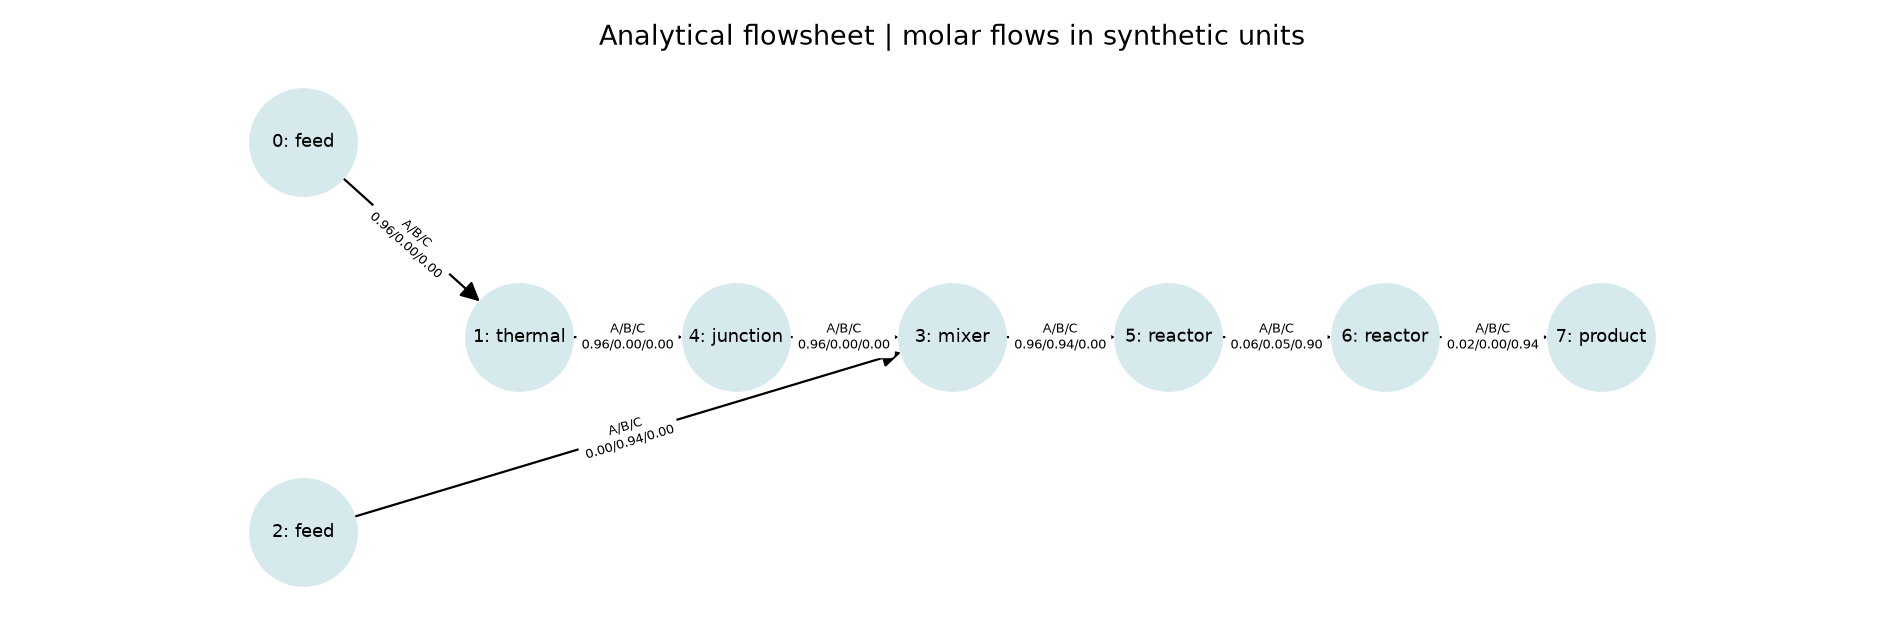

Final feasible: True
Final reward terms: {'product_value': 9.743928924503708, 'utility': -0.46697889255394265, 'capital': -0.9264893426299096, 'complexity': -0.2, 'success': 2.0, 'specification': -0.0, 'open_streams': -0.0, 'failure': -0.0, 'step': -0.01}


: 

In [ ]:
best_record = json.loads((LONG_RUN/"evaluation"/"best_design.json").read_text(encoding="utf-8"))
display(Image(filename=str(LONG_RUN/"evaluation"/"best_design.png")))
print("Recorded best evaluation case:")
print(json.dumps({
    "seed": best_record.get("seed"),
    "return": long_summary["best"]["return"],
    "feasible": best_record["diagnostics"]["feasible"],
    "product_purity": best_record["diagnostics"]["product_purity"],
    "product_recovery": best_record["diagnostics"]["product_recovery"],
}, indent=2))
print("Generate a fresh checkpoint with configs/train_long.yaml to inspect live critic values and actions.")

## 17. What to read next

Follow the exact action path through the source in this order:

1. `config.py` — named settings and validation;
2. `chemistry.py` — immutable material streams;
3. `graph_state.py` — topology and neural features;
4. `actions.py` — hierarchical actions and masks;
5. `environment.py` — reset/step interaction;
6. `units/*.py` — custom process equations;
7. `simulators/low_fidelity.py` — full-graph calculation and feasibility;
8. `models/gnn_encoder.py` — graph message passing;
9. `models/actor_critic.py` — conditional action distributions and critic;
10. `training/rollout.py`, `advantages.py`, `ppo.py` — experience and learning;
11. `evaluation.py` — fixed-case comparison and saved evidence.

The main mental model is:

> Convert the current process graph to features, use a GNN to summarize it, choose one valid construction action, evaluate the resulting graph with explicit equations, and use accumulated experience to improve the neural decision rule.

For deeper prose explanations, open `docs/code_walkthrough.md`. For terminal commands, continuation and long campaigns, open `docs/run_model.md`.